# Stages 1 + 2 + 3 (Track A and Track B) — integrated end-to-end test

**What this measures.** For every new test image, the whole system's final answer — **prawn**, **tuna**, **cetacean** or **none**
(nothing found, or judged a false alarm) — compared with the folder the image came from. It also shows *where* each miss was lost.

**Default since detector v1:** Track B is the YOLOv8 cetacean detector (`TRACK_B_BOX_SOURCE = "detector"`). It finds the animal itself,
so no human box and no SegFormer are needed for cetaceans. The cetacean test photos are the detector's own test split. The layout below
describes the earlier "diagram" setting, which is still available in cell 1 and compared in cell 11.

**Order of execution for each image (follows the pipeline diagram)**
1. **Stage 1** flags anything unusual in the whole frame (texture rule OR local-brightness rule). Shared by both tracks.
2. **Track A:** Stage 2 (SegFormer) segments the **whole frame** and outlines the object; Track A says prawn, tuna or other.
3. **Track B:** does not use SegFormer. For **cetacean images it scores the human annotation box** (a best case: a person drew it). For every
   other image there is no annotation, so it scores **Stage 1's region** (the diagram's "live pipeline" option).
4. Track B is checked first, because Track A has no cetacean class. If P(cetacean) is at or above the cut-off `TRACK_B_TAU`, the answer is **cetacean**.
   Otherwise **Track A** decides: prawn, tuna or other (other = none).

**Read the cetacean result with care.** It uses a box a person drew, so it shows how well Track B classifies a correctly placed box, not whether the
system can find a cetacean on its own. Finding the box is not solved (cell 14 measures Stage 1 and Stage 2 against the annotated animals; cell 11
shows what happens if Stage 1's or SegFormer's box is used for cetaceans instead). Cell 10b reports Track A and Track B separately, as the diagram does.

**Decisions taken in this notebook (change them in cell 1 if you disagree)**
- **Where Track B's box comes from:** `TRACK_B_BOX_SOURCE = "diagram"` (see above). The notebook also scores Stage 1's box and the box around SegFormer's mask for every image, and cell 11 compares all three.
- **Cut-off:** taken from the Track B file (`TRACK_B_USE_SAVED_TAU`), where it was chosen by cross-validation on Track B's own training rows - not from these test images. Cell 11 shows how results change with the cut-off. That table is for reporting; do not pick the cut-off from these test images.
- **One answer per image.** The pipeline works on the largest region, so an image with several animals gets a single label.
- **Cetacean test images = the photos Track B held out.** There is no separate folder of new cetacean photos yet, so the test uses
  the photos Track B v6 **did not train on** (about 20% of its photo groups, chosen by duplicate-group), **one image per photo group**
  so copies do not inflate the score. This is NOT a sealed test: those photos were scored and inspected while Track B was built.
  It is fine for checking that the pieces work together, and for measuring Stage 1 and Stage 2, which never trained on cetaceans.
  Do not present Track B's own numbers from it as a clean result. Replace it with genuinely new cetacean photos when you can.
- **Cetacean photos with an empty or missing label file** are kept out of the headline numbers and reported separately (what an empty file means is still an open question for the team).

**Before you run it**
1. **"New" means new.** Cell 8 compares every test image with everything used in development (including the Track B *training* photos), by picture content, and sets look-alikes aside.
2. **Folder labels must be right.** Each folder must hold frames that really show that class.
3. **Run it once.** If you change anything after seeing these results, the images stop being a clean test.
4. **Track B was trained on small cetacean boxes against water, plus prawn / tuna regions from Stage 2 (v10b).** Expect it to wrongly call some prawn and tuna frames cetacean. Measuring that (cell 10b) is part of this test.

**Needs:** `stage1_final_config.json`, `stage1_bucket_ref.pkl`, `stage2_output/segformer_b0_epoch30.pt`, `stage3_output/track_a_model.pkl`,
`stage3_output/track_b_model_v10b.pkl` (saved by cell 9b of `Stage3_TrackB_Features_v10b_no_overlap.ipynb`: Track B retrained with prawn / tuna / sea negatives and boxes drawn by Stage 2, with its weight, cut-off and feature set chosen by cross-validation on training rows; v10 only uses colour-cast-proof features because the cetacean photos include blue, pink, green, sepia and grey copies). The older v6 file called most prawn and tuna frames 'cetacean' in the first end-to-end run, so it is no longer used.

In [1]:
# --- Cell 1: Imports and config ---
import csv
import json
import pickle
import random
import time
from collections import Counter
from pathlib import Path

import cv2
import numpy as np
from PIL import Image
import torch
import torch.nn.functional as F
from transformers import SegformerForSemanticSegmentation
from skimage.segmentation import slic
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from scipy import ndimage
from scipy.stats import beta
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# --- Trained artefacts ---
STAGE1_CONFIG_PATH = Path("stage1_final_config.json")
STAGE1_BUCKET_REF_PATH = Path("stage1_bucket_ref.pkl")
SEGFORMER_CHECKPOINT_PATH = Path("stage2_output/segformer_b0_epoch30.pt")
TRACK_A_BUNDLE_PATH = Path("stage3_output/track_a_model.pkl")
TRACK_B_BUNDLE_PATH = Path("stage3_output/track_b_model_v10b.pkl")
DETECTOR_VERSION = "v2"     # "v2" = prawn frames added as negatives (Stage3_TrackB_Cetacean_Detector_v2); "v1" = the first detector
DETECTOR_PATH = Path(f"stage3_output/cetacean_detector_{DETECTOR_VERSION}.pt")
DETECTOR_INFO_PATH = Path(f"stage3_output/cetacean_detector_{DETECTOR_VERSION}.json")

# These paths are relative, so they only work if this notebook runs from the folder that holds them. If a file is not
# found there, cell 1 searches your project folders for it (see "find_artefact" below). To stop guessing, paste the full path:
ARTEFACT_OVERRIDES = {
    # "stage1_config":   r"C:\...\stage1_final_config.json",
    # "stage1_bucket":   r"C:\...\stage1_bucket_ref.pkl",
    # "segformer":       r"C:\...\stage2_output\segformer_b0_epoch30.pt",
    # "track_a":         r"C:\...\stage3_output\track_a_model.pkl",
    # "track_b":         r"C:\...\stage3_output\track_b_model_v10b.pkl",
    # "detector":        r"C:\...\Stage_03\stage3_output\cetacean_detector_v1.pt",
    # "detector_info":   r"C:\...\Stage_03\stage3_output\cetacean_detector_v1.json",
}

# --- NEW test images: one folder per TRUE class. UPDATE THESE if your folder names differ. ---
ROOT = Path(r"C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_03")
TEST_ROOT = ROOT / "Test_data"
TEST_DIRS = {
    "prawn": TEST_ROOT / "PRAWNS",               # frames that clearly show a prawn plume (rename to "PRAWN" if that is your folder)
    "tuna":  TEST_ROOT / "TUNA",                 # frames that clearly show tuna boiling
    "clean": TEST_ROOT / "SEA",                  # frames with nothing in them
}

# Cetaceans: the Track B dataset. Only the photos Track B HELD OUT are scored (the saved Track B file lists them).
CETACEAN_IMAGES_DIR = ROOT / "Stage3_TrackB" / "train" / "images"
CETACEAN_LABELS_DIR = ROOT / "Stage3_TrackB" / "train" / "labels"      # YOLO .txt files: class x_center y_center w h (0-1)
CETACEAN_ONE_PER_GROUP = True    # NOTE: the single photo kept per group may be a tinted or grey copy; that is fine, v10 is built for it.
# one image per independent photo group (the dataset holds many copies of the same photo)
TEST_DIRS["cetacean"] = CETACEAN_IMAGES_DIR

# --- How Track B and Track A are combined ---
# "diagram":     the pipeline diagram. Track B does NOT use SegFormer. Cetacean images: the human annotation box (a best case).
#                Every other image: Stage 1's region.
# "stage2_mask": Track B scores the bounding box of Stage 2's mask (SegFormer, which was never trained on cetaceans).
# "stage1":      Track B scores Stage 1's own box for every image, cetaceans included.
# "detector":    Track B is the YOLOv8 cetacean detector: it finds the animal itself, no human box, no SegFormer. (default)
# All of these are always computed, so cell 11 compares them.
TRACK_B_BOX_SOURCE = "detector"
# Which cetacean photos are TEST photos: "detector" = the detector's test split (never trained on by the detector);
# "track_b" = the photos Track B v10b held out (many were in the detector's training, so do not use them with the detector).
CETACEAN_TEST_SOURCE = "detector"
# Track B answer is "cetacean" when P(cetacean) >= TRACK_B_TAU.
# TRACK_B_USE_SAVED_TAU = True: use the cut-off Track B v9 chose by cross-validation on its TRAINING rows (stored in the model file).
# That is not tuned on these test images. If False (or the file has none), TRACK_B_TAU below is used; 0.5 is then just the default.
TRACK_B_USE_SAVED_TAU = True
TRACK_B_TAU = 0.5
TAU_GRID = [0.5, 0.6, 0.7, 0.8, 0.9]      # only used for the sensitivity table in cell 11 (reporting, not selection)

# Optional: set to an int (e.g. 40) for a quick trial run on a few images per class.
MAX_TEST_IMAGES_PER_CLASS = None

# Optional calibration run (cell 15): how often does Track B wrongly say "cetacean" on Val_data tuna and sea frames?
RUN_CALIBRATION = False
CALIBRATION_DIRS = {"tuna": ROOT / "Val_data" / "TUNA", "clean": ROOT / "Val_data" / "SEA"}
CALIBRATION_N = 150

# Optional: COCO annotation JSONs for images ALREADY used in Stage 2/3 development - used only to exclude those exact
# filenames if a TEST_DIRS folder happens to be a superset that also contains them. Leave as None if not needed.
ANNOTATION_JSONS = {
    "prawn": Path("prawn_instances_default_t1.json"),
    "tuna": Path("tuna_instances_default_t1.json"),
}

# --- Everything used during development. Cell 8 checks the test images against these. ---
DEV_IMAGE_DIRS = [
    ROOT.parent / "Stage_02" / "prawn_annotation_training" / "images" / "default",
    ROOT.parent / "Stage_02" / "tuna_annotation_training" / "images" / "default",
    ROOT.parent / "Stage_01" / "data" / "normal_sea" / "heldout_split",
    ROOT.parent / "Stage_01" / "data" / "normal_sea" / "baseline_split",
    ROOT / "Val_data" / "TUNA",                          # used to retrain Track A
    ROOT / "Val_data" / "SEA",                           # used to retrain Track A
    # Track B training photos are added file by file in cell 8, so its held-out photos are not excluded with them.
]
RUN_NEAR_DUPLICATE_AUDIT = True
# Featureless open water naturally scores high similarity against OTHER unrelated open water at low resolution,
# so clean water needs a higher bar. Per-class thresholds; default 0.95.
NEAR_DUPLICATE_THRESHOLD = {"prawn": 0.95, "tuna": 0.95, "clean": 0.985, "cetacean": 0.99, "cetacean_empty": 0.995}   # cetacean: tiny animals on open water barely change a 32x32 thumbnail, so only near-identical copies count
EXCLUDE_SUSPECTED_DUPLICATES = True

# --- Settings that must match what Track A was trained with (checked below against the saved model) ---
STAGE2_PROB_THRESHOLD = 0.35
STAGE2_MIN_MASK_PIXELS = 80
STAGE1_DILATION_ITERS = 2
CROP_PADDING_PX = 20
RING_PX = 25
MIN_NATIVE_PX = 24
MIN_NATIVE_MASK_PX = 30

# --- Stage 2 route (NOT part of the Track A guard) ---
# "whole_frame": SegFormer sees the whole photograph. "crop": the old behaviour (Stage 1's padded box only).
STAGE2_ROUTE = "whole_frame"
STAGE2_WHOLE_FRAME_PROB = 0.35      # kept equal to the value Track A was trained with
STAGE2_KEEP_LARGEST_BLOB = True     # Track A was built for one object per image

OUTPUT_DIR = Path("stage1234_test_output")
OUTPUT_DIR.mkdir(exist_ok=True)

missing = [f"{k}: {v}" for k, v in TEST_DIRS.items() if not Path(v).exists()]
if not Path(CETACEAN_LABELS_DIR).exists():
    missing.append(f"cetacean labels: {CETACEAN_LABELS_DIR}")
if missing:
    raise RuntimeError("These test folders were not found - fix the paths at the top of this cell:\n  " + "\n  ".join(missing))
if TRACK_B_BOX_SOURCE not in ("detector", "diagram", "stage2_mask", "stage1"):
    raise RuntimeError("TRACK_B_BOX_SOURCE must be 'detector', 'diagram', 'stage2_mask' or 'stage1'")

# ---- find the trained files (they were saved by other notebooks, probably from a different working folder) ----
import os
print("This notebook is running from:", Path.cwd())
SEARCH_ROOTS = []
for _r in (Path.cwd(), ROOT.parent, ROOT):
    if _r.exists() and _r.resolve() not in [s.resolve() for s in SEARCH_ROOTS]:
        SEARCH_ROOTS.append(_r)

def find_artefact(key, rel_path, made_by):
    """Return the path to a trained file: override -> relative path as written -> search the project folders (newest first)."""
    if key in ARTEFACT_OVERRIDES:
        p = Path(ARTEFACT_OVERRIDES[key])
        if not p.exists():
            raise FileNotFoundError(f"ARTEFACT_OVERRIDES['{key}'] points to a file that does not exist: {p}")
        return p, [p]
    if Path(rel_path).exists():
        return Path(rel_path), [Path(rel_path)]
    hits = {}
    for root in SEARCH_ROOTS:
        for dirpath, dirnames, filenames in os.walk(root):
            dirnames[:] = [d for d in dirnames if d not in (".git", "__pycache__", ".ipynb_checkpoints", "node_modules")]
            if rel_path.name in filenames:
                full = Path(dirpath) / rel_path.name
                hits[str(full.resolve())] = full
            if len(filenames) > 300:          # an image folder - nothing we are looking for lives inside it
                dirnames[:] = []
    cands = sorted(hits.values(), key=lambda p: p.stat().st_mtime, reverse=True)
    if not cands:
        raise FileNotFoundError(f"Could not find '{rel_path.name}' anywhere under {[str(r) for r in SEARCH_ROOTS]}.\n"
                                f"  It is created by: {made_by}.\n"
                                f"  Run that notebook (its save cell) first, or set ARTEFACT_OVERRIDES['{key}'] to the full path.")
    return cands[0], cands

def _report(key, chosen, cands):
    import datetime
    t = datetime.datetime.fromtimestamp(chosen.stat().st_mtime).strftime("%Y-%m-%d %H:%M")
    print(f"  {key:<14} {chosen}   (saved {t})")
    if len(cands) > 1:
        print(f"                 {len(cands)} copies found; using the newest. Others: " + "; ".join(str(c) for c in cands[1:4]))

_found = {}
for _key, _rel, _by in [
    ("stage1_bucket", STAGE1_BUCKET_REF_PATH, "the Stage 1 notebook"),
    ("segformer",     SEGFORMER_CHECKPOINT_PATH, "Stage_02_Pipeline_FINAL (training cell)"),
    ("track_a",       TRACK_A_BUNDLE_PATH, "Stage_03_TrackA_v4_with_images_v3 (save cell, cell 17)"),
    ("track_b",       TRACK_B_BUNDLE_PATH, "Stage3_TrackB_Features_v10b_no_overlap (cell 9b)"),
    ("detector",      DETECTOR_PATH, f"Stage3_TrackB_Cetacean_Detector_{DETECTOR_VERSION} (cell 9)"),
    ("detector_info", DETECTOR_INFO_PATH, f"Stage3_TrackB_Cetacean_Detector_{DETECTOR_VERSION} (cell 9)"),
]:
    _found[_key] = find_artefact(_key, _rel, _by)
SEGFORMER_CHECKPOINT_LABEL = SEGFORMER_CHECKPOINT_PATH        # the text Track A recorded (compared below)
SEGFORMER_CHECKPOINT_PATH = _found["segformer"][0]
TRACK_A_BUNDLE_PATH = _found["track_a"][0]
TRACK_B_BUNDLE_PATH = _found["track_b"][0]
DETECTOR_PATH = _found["detector"][0]
DETECTOR_INFO_PATH = _found["detector_info"][0]
with open(DETECTOR_INFO_PATH) as f:
    DET_INFO = json.load(f)
DETECTOR_CONF = float(DET_INFO["confidence_cutoff"])             # chosen on the detector's VALIDATION split
DET_IMG_SIZE = int(DET_INFO.get("img_size", 352))
DET_TAU_GRID = sorted(set([0.1, 0.2, 0.3, 0.5, 0.7] + [DETECTOR_CONF]))
STAGE1_BUCKET_REF_PATH = _found["stage1_bucket"][0]

with open(TRACK_A_BUNDLE_PATH, "rb") as f:
    bundle = pickle.load(f)

# Stage 1 config: if several copies exist, use the one identical to the config Track A recorded.
_cfg_chosen, _cfg_cands = find_artefact("stage1_config", STAGE1_CONFIG_PATH, "the Stage 1 notebook")
for _c in _cfg_cands:
    with open(_c) as _f:
        if json.load(_f) == bundle["stage1_config"]:
            _cfg_chosen = _c
            break
STAGE1_CONFIG_PATH = _cfg_chosen
_found["stage1_config"] = (_cfg_chosen, _cfg_cands)

print("Trained files being used:")
for _k in ("stage1_config", "stage1_bucket", "segformer", "track_a", "track_b"):
    _report(_k, *_found[_k])

with open(STAGE1_CONFIG_PATH) as f:
    stage1_config = json.load(f)
with open(STAGE1_BUCKET_REF_PATH, "rb") as f:
    stage1_bucket_ref = pickle.load(f)

# ---- refuse to run if anything differs from what Track A was trained with ----
mine = {"prob": STAGE2_PROB_THRESHOLD, "min_px": STAGE2_MIN_MASK_PIXELS, "dilation": STAGE1_DILATION_ITERS,
        "crop_pad": CROP_PADDING_PX, "ring_px": RING_PX, "min_native_px": MIN_NATIVE_PX,
        "min_native_mask_px": MIN_NATIVE_MASK_PX}
mismatch = {k: (bundle["settings"].get(k), v) for k, v in mine.items() if bundle["settings"].get(k) != v}
if bundle["stage1_config"] != stage1_config:
    mismatch["stage1_config"] = "the Stage 1 config file differs from the one Track A was trained with"
if Path(str(bundle["segformer_checkpoint"]).replace("\\", "/")).name != Path(str(SEGFORMER_CHECKPOINT_LABEL)).name:
    mismatch["segformer_checkpoint"] = (bundle["segformer_checkpoint"], str(SEGFORMER_CHECKPOINT_LABEL))
if mismatch:
    raise RuntimeError(f"Settings differ from what Track A was trained with, so results would not be valid: {mismatch}")

IMG_SIZE = tuple(stage1_config["img_size"])
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TRACK_A_MODEL = bundle["model"]
TRACK_A_COLS = bundle["columns"]
TRACK_A_CLASSES = list(bundle["classes"])
print(f"Settings match. Track A: feature set '{bundle['feature_set']}', trained on {bundle['n_train_rows']} rows "
      f"{bundle['train_class_counts']}.  Device: {device}")
random.seed(42)
np.random.seed(42)

This notebook is running from: C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Combined Pipeline
Trained files being used:
  stage1_config  stage1_final_config.json   (saved 2026-09-22 17:53)
  stage1_bucket  stage1_bucket_ref.pkl   (saved 2026-09-22 17:53)
  segformer      C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Combined Pipeline\segformer_b0_epoch30.pt   (saved 2026-10-09 20:50)
                 3 copies found; using the newest. Others: C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_02\stage2_output\segformer_b0_epoch30.pt; C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_03\stage2_output\segformer_b0_epoch30.pt
  track_a        C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Combined Pipeline\track_a_model.pkl   (saved 2026-09-30 14:21)
                 2 copies found; using the newest. Others: C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Sta

In [2]:
# --- Cell 2: Load SegFormer-B0 with the best checkpoint ---

model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b0-finetuned-ade-512-512", num_labels=2,
    id2label={0: "background", 1: "anomaly"}, label2id={"background": 0, "anomaly": 1},
    ignore_mismatched_sizes=True,
)
model.load_state_dict(torch.load(SEGFORMER_CHECKPOINT_PATH, map_location=device))
model.to(device)
model.eval()
print(f"Loaded checkpoint: {SEGFORMER_CHECKPOINT_PATH}")

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Loaded checkpoint: C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Combined Pipeline\segformer_b0_epoch30.pt


In [3]:
# --- Cell 3: Ported Stage 1 detector (texture rule OR local-brightness rule) ---

S1_N_SEGMENTS = stage1_config["n_segments"]
S1_COMPACTNESS = stage1_config["compactness"]
S1_GLCM_LEVELS = stage1_config["glcm_levels"]
S1_Z_THRESH = stage1_config["z_thresh"]
S1_GLINT_THRESH = stage1_config["glint_thresh"]
S1_MIN_COMPONENT_AREA_PX = stage1_config["min_component_area_px"]
S1_MIN_FEATURES_FLAGGED = stage1_config["min_features_flagged"]
S1_BUCKET_EDGES = np.array(stage1_config["bucket_edges"])
S1_LOCAL_Z_THRESH = stage1_config.get("local_z_thresh", 999)
S1_MIN_AREA_LOCAL = stage1_config.get("min_area_local", 999999999)
FEATURE_KEYS = ["contrast_L", "homogeneity_L", "energy_L", "contrast_a", "lbp_var"]

def suppress_glint(img_bgr, thresh=S1_GLINT_THRESH, dilate_iter=2):
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    L = lab[:, :, 0]
    glint_mask = (L > thresh).astype(np.uint8)
    kernel = np.ones((5, 5), np.uint8)
    glint_mask = cv2.dilate(glint_mask, kernel, iterations=dilate_iter)
    return cv2.morphologyEx(glint_mask, cv2.MORPH_CLOSE, kernel)

def preprocess_image_s1(path, glint_thresh=S1_GLINT_THRESH):
    img_bgr = cv2.resize(cv2.imread(str(path)), IMG_SIZE)
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    glint_mask = suppress_glint(img_bgr, glint_thresh)
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    return lab, glint_mask, rgb

def quantize_s1(patch, levels=S1_GLCM_LEVELS):
    return (patch.astype(np.float32) / 256 * levels).astype(np.uint8)

def glcm_props_s1(patch_q, levels=S1_GLCM_LEVELS):
    glcm = graycomatrix(patch_q, distances=[1], angles=[0], levels=levels, symmetric=True, normed=True)
    return (float(graycoprops(glcm, 'contrast')[0, 0]), float(graycoprops(glcm, 'homogeneity')[0, 0]), float(graycoprops(glcm, 'energy')[0, 0]))

def extract_superpixel_features_s1(img_lab, glint_mask, n_segments=S1_N_SEGMENTS, compactness=S1_COMPACTNESS):
    L_channel, a_channel = img_lab[:, :, 0], img_lab[:, :, 1]
    segments = slic(img_lab, n_segments=n_segments, compactness=compactness, start_label=1)
    objects = ndimage.find_objects(segments)
    features = []
    for seg_id, bbox in enumerate(objects, start=1):
        if bbox is None:
            continue
        y_slice, x_slice = bbox
        local_mask = segments[y_slice, x_slice] == seg_id
        if glint_mask[y_slice, x_slice][local_mask].mean() > 0.5:
            continue
        patch_L, patch_a = L_channel[y_slice, x_slice], a_channel[y_slice, x_slice]
        if patch_L.shape[0] < 2 or patch_L.shape[1] < 2:
            continue
        contrast_L, homogeneity_L, energy_L = glcm_props_s1(quantize_s1(patch_L))
        contrast_a, _, _ = glcm_props_s1(quantize_s1(patch_a))
        lbp_var = float(np.var(local_binary_pattern(patch_L, P=8, R=1, method='uniform')))
        features.append({"seg_id": int(seg_id), "contrast_L": contrast_L, "homogeneity_L": homogeneity_L,
                          "energy_L": energy_L, "contrast_a": contrast_a, "lbp_var": lbp_var, "mean_L": float(patch_L.mean())})
    return segments, features

def image_sea_state_score(img_lab, glint_mask):
    L = img_lab[:, :, 0]
    valid = glint_mask == 0
    return float(np.mean(L[valid] if valid.any() else L))

def assign_bucket_from_score(score, edges=S1_BUCKET_EDGES):
    return int(np.searchsorted(edges, score))

def score_region_deviation_s1(feat, baseline_ref, z_thresh, min_features_flagged):
    z_scores = {k: abs(feat[k] - baseline_ref[k][0]) / (baseline_ref[k][1] + 1e-6) for k in FEATURE_KEYS}
    return sum(1 for z in z_scores.values() if z > z_thresh) >= min_features_flagged

def _region_with_bbox(flagged_mask, min_area, dilation_iters=STAGE1_DILATION_ITERS):
    if dilation_iters > 0:
        flagged_mask = ndimage.binary_dilation(flagged_mask, iterations=dilation_iters)
    labeled, n_components = ndimage.label(flagged_mask)
    if n_components == 0:
        return False, 0, None
    sizes = ndimage.sum(flagged_mask, labeled, range(1, n_components + 1))
    biggest_label = int(np.argmax(sizes)) + 1
    max_component = float(sizes[biggest_label - 1])
    is_detected = max_component >= min_area
    bbox = None
    if is_detected:
        y_slice, x_slice = ndimage.find_objects(labeled)[biggest_label - 1]
        bbox = (x_slice.start, y_slice.start, x_slice.stop, y_slice.stop)
    return is_detected, max_component, bbox

def texture_rule_with_bbox(segments, feats, baseline_ref, z_thresh=S1_Z_THRESH, min_area=S1_MIN_COMPONENT_AREA_PX, min_features_flagged=S1_MIN_FEATURES_FLAGGED):
    flagged_ids = {f["seg_id"] for f in feats if score_region_deviation_s1(f, baseline_ref, z_thresh, min_features_flagged)}
    if not flagged_ids:
        return False, 0, None
    return _region_with_bbox(np.isin(segments, list(flagged_ids)), min_area)

def local_brightness_rule_with_bbox(feats, segments, local_z_thresh=S1_LOCAL_Z_THRESH, min_area_local=S1_MIN_AREA_LOCAL):
    if not feats:
        return False, 0, None
    mean_Ls = np.array([f["mean_L"] for f in feats])
    img_mean, img_std = mean_Ls.mean(), mean_Ls.std()
    flagged_ids = {f["seg_id"] for f in feats if abs(f["mean_L"] - img_mean) / (img_std + 1e-6) > local_z_thresh}
    if not flagged_ids:
        return False, 0, None
    return _region_with_bbox(np.isin(segments, list(flagged_ids)), min_area_local)

def get_flagging_result_with_bbox(segments, feats, baseline_ref):
    tex_detected, tex_area, tex_bbox = texture_rule_with_bbox(segments, feats, baseline_ref)
    local_detected, local_area, local_bbox = local_brightness_rule_with_bbox(feats, segments)
    if not tex_detected and not local_detected:
        return False, 0, None
    if tex_detected and local_detected:
        return (True, tex_area, tex_bbox) if tex_area >= local_area else (True, local_area, local_bbox)
    return (True, tex_area, tex_bbox) if tex_detected else (True, local_area, local_bbox)

print("Stage 1 detector ported and ready.")

Stage 1 detector ported and ready.


In [4]:
# --- Cell 4: Connected pipeline (Stage 1 -> Stage 2 on the WHOLE frame -> crop for Track A) ---
#
# What changed from the old version:
#   OLD: Stage 1's box (+20 px) was cut out and resized to 512x512 BEFORE SegFormer saw it. If Stage 1's box missed
#        the anomaly (the green box in the gallery), the anomaly was physically absent from Stage 2's input.
#   NEW: SegFormer sees the whole frame, so a misplaced Stage 1 box can no longer hide the object. The crop is made
#        AFTER Stage 2, around the mask, so Track A still receives the kind of input it was trained on.
#
# Result keys (unchanged names, so the later cells keep working):
#   bbox         crop region in 512x512 frame coordinates (what Track A's features use)
#   s1_bbox      Stage 1's own padded box, kept so the gallery can show where Stage 1 pointed
#   crop         float32 0-1, 512x512, the image Track A measures
#   stage2_mask  0/1, 512x512, in CROP space (lines up with `crop`)

def _segformer_probs(rgb_u8):
    """uint8 RGB image of any size -> anomaly probability at IMG_SIZE (rows = IMG_SIZE[1], cols = IMG_SIZE[0])."""
    arr = np.array(Image.fromarray(rgb_u8).resize(IMG_SIZE, Image.BILINEAR), dtype=np.float32) / 255.0
    arr = (arr - IMAGENET_MEAN) / IMAGENET_STD
    pixel_values = torch.from_numpy(arr.transpose(2, 0, 1)).unsqueeze(0).to(device)
    with torch.no_grad():
        logits = model(pixel_values=pixel_values).logits
        logits = F.interpolate(logits, size=(IMG_SIZE[1], IMG_SIZE[0]), mode="bilinear", align_corners=False)
        return F.softmax(logits, dim=1)[0, 1].cpu().numpy()

def _pad_box(box, pad, W, H):
    x0, y0, x1, y1 = box
    return max(0, x0 - pad), max(0, y0 - pad), min(W, x1 + pad), min(H, y1 + pad)

def _boxes_overlap(a, b):
    return min(a[2], b[2]) > max(a[0], b[0]) and min(a[3], b[3]) > max(a[1], b[1])

def _largest_blob(mask):
    labeled, n = ndimage.label(mask)
    if n <= 1:
        return mask
    sizes = ndimage.sum(mask, labeled, range(1, n + 1))
    return (labeled == (int(np.argmax(sizes)) + 1)).astype(mask.dtype)

def run_connected_pipeline(path, bucket_ref=stage1_bucket_ref, route=None):
    route = route or STAGE2_ROUTE
    lab, glint_mask, rgb = preprocess_image_s1(path)
    segments, feats = extract_superpixel_features_s1(lab, glint_mask)
    bucket = assign_bucket_from_score(image_sea_state_score(lab, glint_mask))
    is_detected, max_component, bbox = get_flagging_result_with_bbox(segments, feats, bucket_ref[bucket])

    result = {"path": str(path), "rgb": rgb, "is_detected": is_detected,
              "bbox": None, "s1_bbox": None, "crop": None, "stage2_mask": None, "n_flagged_px_stage2": 0,
              "stage2_raw_px": 0, "stage2_max_prob": None, "route": route}
    if not (is_detected and bbox is not None):
        return result

    H, W = rgb.shape[:2]
    s1_box = _pad_box(bbox, CROP_PADDING_PX, W, H)
    result["s1_bbox"] = s1_box

    # ---------------- OLD route: Stage 2 only sees Stage 1's padded box ----------------
    if route == "crop":
        x0p, y0p, x1p, y1p = s1_box
        crop = rgb[y0p:y1p, x0p:x1p]
        result["bbox"] = s1_box
        if crop.size == 0:
            return result
        crop_arr = np.array(Image.fromarray(crop).resize(IMG_SIZE, Image.BILINEAR), dtype=np.float32) / 255.0
        probs = _segformer_probs(crop)
        pred = (probs > STAGE2_PROB_THRESHOLD).astype(np.uint8)
        result["stage2_raw_px"] = int(pred.sum())
        result["stage2_max_prob"] = float(probs.max())
        if pred.sum() < STAGE2_MIN_MASK_PIXELS:
            pred = np.zeros_like(pred)
        result["crop"], result["stage2_mask"], result["n_flagged_px_stage2"] = crop_arr, pred, int(pred.sum())
        return result

    # ---------------- NEW route: Stage 2 sees the whole frame ----------------
    probs = _segformer_probs(rgb)                       # rgb is already IMG_SIZE, so this is frame space
    pred = (probs > STAGE2_WHOLE_FRAME_PROB).astype(np.uint8)
    result["stage2_raw_px"] = int(pred.sum())            # pixels above threshold anywhere in the frame
    result["stage2_max_prob"] = float(probs.max())
    if STAGE2_KEEP_LARGEST_BLOB and pred.any():
        pred = _largest_blob(pred)
    if pred.sum() < STAGE2_MIN_MASK_PIXELS:
        pred = np.zeros_like(pred)

    if pred.sum() == 0:
        # Nothing found. Keep the whole frame as "crop" so the gallery shows what Stage 2 was looking at.
        result["bbox"] = s1_box
        result["crop"] = rgb.astype(np.float32) / 255.0
        result["stage2_mask"] = np.zeros((IMG_SIZE[1], IMG_SIZE[0]), np.uint8)
        return result

    # Crop for Track A: around the mask. Where Stage 2 agrees with Stage 1's box (they overlap) the crop is the union
    # of the two, which is what Track A was trained on; where they disagree, Stage 1's box was in the wrong place and
    # only the mask's own box is used.
    ys, xs = np.where(pred > 0)
    mask_box = _pad_box((int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1), CROP_PADDING_PX, W, H)
    if _boxes_overlap(mask_box, s1_box):
        crop_box = (min(mask_box[0], s1_box[0]), min(mask_box[1], s1_box[1]),
                    max(mask_box[2], s1_box[2]), max(mask_box[3], s1_box[3]))
    else:
        crop_box = mask_box
    x0, y0, x1, y1 = crop_box
    crop_arr = np.array(Image.fromarray(rgb[y0:y1, x0:x1]).resize(IMG_SIZE, Image.BILINEAR), dtype=np.float32) / 255.0
    mask_crop = cv2.resize(pred[y0:y1, x0:x1], IMG_SIZE, interpolation=cv2.INTER_NEAREST)
    result["bbox"], result["crop"], result["stage2_mask"] = crop_box, crop_arr, mask_crop
    result["n_flagged_px_stage2"] = int(mask_crop.sum())
    return result

print(f"Connected pipeline ready. Stage 2 route = {STAGE2_ROUTE!r}"
      + (f", probability cut-off {STAGE2_WHOLE_FRAME_PROB}, keep largest blob = {STAGE2_KEEP_LARGEST_BLOB}"
         if STAGE2_ROUTE == "whole_frame" else f", probability cut-off {STAGE2_PROB_THRESHOLD}"))

Connected pipeline ready. Stage 2 route = 'whole_frame', probability cut-off 0.35, keep largest blob = True


In [5]:
# --- Cell 6: Track A features: shape, signature (as-is and native-scale), scene, scale diagnostics ---

LABELS = ["prawn", "tuna", "other"]

def _sobel_mag(gray):
    return np.sqrt(cv2.Sobel(gray, cv2.CV_32F, 1, 0) ** 2 + cv2.Sobel(gray, cv2.CV_32F, 0, 1) ** 2)

def texture_at_native_scale(crop_u8, mask, bbox, src_size):
    """Texture measured on the crop shrunk back to the ORIGINAL file's pixel grid, so it is not
    inflated or deflated by our own resizing. The box covers (box_w x src_w / 512) file pixels across;
    the 512x512 crop is shrunk to that size (never enlarged, never below MIN_NATIVE_PX)."""
    x0, y0, x1, y1 = bbox
    src_w, src_h = src_size
    fw, fh = IMG_SIZE
    nw = int(np.clip(round((x1 - x0) * src_w / fw), MIN_NATIVE_PX, fw))
    nh = int(np.clip(round((y1 - y0) * src_h / fh), MIN_NATIVE_PX, fh))
    small = cv2.resize(crop_u8, (nw, nh), interpolation=cv2.INTER_AREA)
    m_small = cv2.resize(mask.astype(np.float32), (nw, nh), interpolation=cv2.INTER_AREA) > 0.5
    if m_small.sum() < MIN_NATIVE_MASK_PX:
        return None
    gray = cv2.cvtColor(small, cv2.COLOR_RGB2GRAY).astype(np.float32)
    L = cv2.cvtColor(small, cv2.COLOR_RGB2LAB)[:, :, 0].astype(np.float32)
    return float(L[m_small].std()), float(_sobel_mag(gray)[m_small].mean()), nw

def extract_track_a_features(result):
    """Returns (features, None) on success, or (None, reason) if the row is unusable.
    Needs 'stage2_mask' (512x512 0/1), 'crop' (512x512x3 float 0-1 RGB), 'bbox' and 'path'."""
    mask, crop, bbox = result.get("stage2_mask"), result.get("crop"), result.get("bbox")
    if mask is None or crop is None or bbox is None:
        return None, "missing crop/mask/box"
    mask_area = int(mask.sum())
    if mask_area == 0:
        return None, "empty mask"
    inside = mask.astype(bool)

    # ---- shape (baseline only) ----
    ys, xs = np.where(inside)
    mask_h = ys.max() - ys.min() + 1
    mask_w = xs.max() - xs.min() + 1
    elongation = max(mask_w, mask_h) / max(1, min(mask_w, mask_h))
    extent = mask_area / (mask_w * mask_h)
    fill_ratio = mask_area / mask.size                       # fraction of the crop covered by the mask

    # ---- pixel content on the stretched 512x512 crop ----
    crop_u8 = (np.clip(crop, 0, 1) * 255).astype(np.uint8)   # RGB
    lab = cv2.cvtColor(crop_u8, cv2.COLOR_RGB2LAB).astype(np.float32)
    gray = cv2.cvtColor(crop_u8, cv2.COLOR_RGB2GRAY).astype(np.float32)
    grad = _sobel_mag(gray)
    L, a, b = lab[:, :, 0], lab[:, :, 1], lab[:, :, 2]

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * RING_PX + 1, 2 * RING_PX + 1))
    ring = cv2.dilate(mask.astype(np.uint8), kernel).astype(bool) & ~inside
    if ring.sum() < 50:
        ring = ~inside
    if ring.sum() < 50:
        return None, "mask covers almost the whole crop"

    # ---- native-scale texture + scale diagnostics ----
    with Image.open(result["path"]) as im:
        src_size = im.size                                    # (width, height) of the original file
    native = texture_at_native_scale(crop_u8, mask, bbox, src_size)
    if native is None:
        return None, "mask too small at native scale"
    in_L_std_native, in_edge_native, native_w = native

    box_w = max(1, bbox[2] - bbox[0])
    return {
        # shape
        "fill_ratio": fill_ratio, "elongation": elongation, "extent": extent,
        # signature, measured on the stretched crop (kept as a diagnostic)
        "in_L_std": float(L[inside].std()), "in_edge": float(grad[inside].mean()),
        # signature, measured at native scale
        "in_L_std_native": in_L_std_native, "in_edge_native": in_edge_native,
        "contrast_ring": float(L[inside].mean() - L[ring].mean()),
        # scene
        "in_L": float(L[inside].mean()), "ring_L": float(L[ring].mean()),
        "in_a": float(a[inside].mean()), "ring_a": float(a[ring].mean()),
        "in_b": float(b[inside].mean()), "ring_b": float(b[ring].mean()),
        # scale diagnostics
        "crop_scale": IMG_SIZE[0] / box_w,                                   # stretch of Stage 1's box to 512
        "total_upscale": IMG_SIZE[0] * IMG_SIZE[0] / (box_w * src_size[0]),  # stretch relative to the real photo
        "src_w": float(src_size[0]), "native_w": float(native_w),
    }, None

print("Feature function ready.")

Feature function ready.


In [6]:
# --- Cell 6: Track B - load the saved model and define how a region is scored ---
# Track B scores a box by comparing the water inside it with a ring of water around it (shape + colour/brightness).
# It was trained on full-resolution photographs, so here it reads the ORIGINAL file at full size and the 512x512
# pipeline coordinates are scaled up to match.

with open(TRACK_B_BUNDLE_PATH, "rb") as f:
    bundle_b = pickle.load(f)
TRACK_B_MODEL = bundle_b["model"]
TRACK_B_COLS = bundle_b["columns"]
TRACK_B_POS = bundle_b["positive_index"]             # which predict_proba column is P(cetacean)
assert bundle_b["classes"][TRACK_B_POS] == "cetacean", "Track B file: positive class is not 'cetacean'"
_bs = bundle_b["settings"]                           # the exact feature settings the model was trained with
RING_PAD_FRAC = _bs["ring_pad_frac"]
BAR_MEAN_THRESH = _bs["bar_mean_thresh"]
MIN_BAR_PX = _bs["min_bar_px"]
BAR_MARGIN_PX = _bs["bar_margin_px"]
BLACK_L_THRESH = _bs["black_l_thresh"]
_saved_tau = bundle_b["training"].get("selected_tau")
if TRACK_B_USE_SAVED_TAU and _saved_tau is not None:
    TRACK_B_TAU = float(_saved_tau)
    TAU_GRID = sorted(set(TAU_GRID + [TRACK_B_TAU]))
    print(f"Cut-off taken from the Track B file: {TRACK_B_TAU}")
else:
    print(f"Cut-off from this notebook's config: {TRACK_B_TAU}")
print(f"Track B loaded: feature set '{bundle_b['feature_set']}' {TRACK_B_COLS}")
print(f"  trained on {bundle_b['training']['n_train_rows']} rows {bundle_b['training']['train_class_counts']}; "
      f"held-out accuracy at training time {bundle_b['training']['heldout_accuracy']:.3f}")
print(f"  feature settings (taken from the file): {_bs}")

from ultralytics import YOLO
DETECTOR = YOLO(str(DETECTOR_PATH))
print(f"Cetacean detector loaded: {DETECTOR_PATH.name}, image size {DET_IMG_SIZE}, cut-off {DETECTOR_CONF} (from its validation split)")
_dr = DET_INFO.get("results", {})
if _dr.get("test_cetacean_images"):
    print(f"  its own test split: {_dr['test_cetacean_images'][0]}/{_dr['test_cetacean_images'][1]} cetacean images found")

def detect_cetaceans(path):
    """All boxes the detector draws (confidence >= 0.05), in the photograph's own pixel coordinates."""
    r = DETECTOR.predict(str(path), imgsz=DET_IMG_SIZE, conf=0.05, verbose=False)[0]
    return list(zip(r.boxes.conf.cpu().numpy().tolist(), r.boxes.xyxy.cpu().numpy().tolist()))


def detect_content_box(img_rgb, bar_mean_thresh=BAR_MEAN_THRESH, min_bar_px=MIN_BAR_PX, margin=BAR_MARGIN_PX):
    """Finds the picture area inside black letterbox bars (same code as Track B v6)."""
    H, W = img_rgb.shape[:2]
    col_profile = img_rgb[::8].max(axis=2).mean(axis=0)
    row_profile = img_rgb[:, ::8].max(axis=2).mean(axis=1)

    def trim(profile, n):
        good = np.flatnonzero(profile >= bar_mean_thresh)
        if good.size == 0:
            return 0, n
        lo, hi = int(good[0]), int(good[-1]) + 1
        lo = lo + margin if lo >= min_bar_px else 0
        hi = hi - margin if (n - hi) >= min_bar_px else n
        return lo, hi

    x0, x1 = trim(col_profile, W)
    y0, y1 = trim(row_profile, H)
    if (x1 - x0) < 0.3 * W or (y1 - y0) < 0.3 * H:
        return 0, 0, W, H, False
    return x0, y0, x1, y1, (x0, y0, x1, y1) != (0, 0, W, H)


def extract_box_features(img_rgb, box, content=None, lab=None, ring_pad_frac=RING_PAD_FRAC):
    """Same code as Track B v10 (v6 features plus the tint-robust ones). box = (x0, y0, x1, y1) in pixels. Returns a feature dict, or None."""
    H, W = img_rgb.shape[:2]
    cx0, cy0, cx1, cy1 = content if content is not None else (0, 0, W, H)
    if lab is None:
        lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
    x0, y0, x1, y1 = [int(round(v)) for v in box]
    x0, y0 = max(cx0, x0), max(cy0, y0)
    x1, y1 = min(cx1, x1), min(cy1, y1)
    bw, bh = x1 - x0, y1 - y0
    if bw < 4 or bh < 4:
        return None
    pad_x, pad_y = int(bw * ring_pad_frac), int(bh * ring_pad_frac)
    rx0, ry0 = max(cx0, x0 - pad_x), max(cy0, y0 - pad_y)
    rx1, ry1 = min(cx1, x1 + pad_x), min(cy1, y1 + pad_y)
    region = lab[ry0:ry1, rx0:rx1]
    ring_mask = np.ones(region.shape[:2], dtype=bool)
    ring_mask[y0 - ry0:y1 - ry0, x0 - rx0:x1 - rx0] = False
    ring = region[ring_mask]
    inside = lab[y0:y1, x0:x1].reshape(-1, 3)
    ring = ring[ring[:, 0] > BLACK_L_THRESH]
    inside = inside[inside[:, 0] > BLACK_L_THRESH]
    if ring.shape[0] < 20 or inside.shape[0] < 0.5 * bw * bh:
        return None
    aspect_ratio = max(bw, bh) / max(1, min(bw, bh))
    relative_area = (bw * bh) / ((cx1 - cx0) * (cy1 - cy0))
    in_L, in_a, in_b = inside[:, 0], inside[:, 1], inside[:, 2]
    r_L, r_a, r_b = ring[:, 0], ring[:, 1], ring[:, 2]
    return {
        "aspect_ratio": aspect_ratio, "relative_area": relative_area,
        "in_L": float(in_L.mean()), "ring_L": float(r_L.mean()), "contrast_L": float(in_L.mean() - r_L.mean()),
        "in_a": float(in_a.mean()), "ring_a": float(r_a.mean()),
        "in_b": float(in_b.mean()), "ring_b": float(r_b.mean()),
        "in_L_std": float(in_L.std()),
        # tint-robust features added in Track B v10 (differences / ratios, so a colour cast cancels out)
        "d_a": float(in_a.mean() - r_a.mean()),
        "d_b": float(in_b.mean() - r_b.mean()),
        "chroma_contrast": float(np.hypot(in_a.mean() - r_a.mean(), in_b.mean() - r_b.mean())),
        "L_ratio": float(in_L.mean() / max(float(r_L.mean()), 1.0)),
        "in_L_cv": float(in_L.std() / max(float(in_L.mean()), 1.0)),
    }


class TrackBImage:
    """Reads one photograph at full size ONCE, so several boxes can be scored cheaply."""

    def __init__(self, path):
        self.img = np.array(Image.open(path).convert("RGB"))
        self.H, self.W = self.img.shape[:2]
        self.content = detect_content_box(self.img)[:4]
        self.lab = cv2.cvtColor(self.img, cv2.COLOR_RGB2LAB).astype(np.float32)

    def p_cetacean_native(self, box):
        """box in the photograph's own pixel coordinates -> P(cetacean), or None if the box cannot be measured."""
        feats = extract_box_features(self.img, box, content=self.content, lab=self.lab)
        if feats is None:
            return None
        x = np.array([[feats[c] for c in TRACK_B_COLS]], dtype=float)
        return float(TRACK_B_MODEL.predict_proba(x)[0, TRACK_B_POS])

    def p_cetacean_frame(self, box512):
        """box in the 512x512 pipeline frame -> P(cetacean)."""
        if box512 is None:
            return None
        sx, sy = self.W / IMG_SIZE[0], self.H / IMG_SIZE[1]
        x0, y0, x1, y1 = box512
        return self.p_cetacean_native((x0 * sx, y0 * sy, x1 * sx, y1 * sy))


# ---- cetacean ground truth: YOLO label files ----
label_files = {p.stem: p for p in Path(CETACEAN_LABELS_DIR).rglob("*.txt")}

def load_yolo_boxes(txt_path, img_w, img_h):
    """Returns a list of (class_id, x0, y0, x1, y1) in PIXEL coordinates."""
    boxes = []
    for line in txt_path.read_text().strip().splitlines():
        parts = line.split()
        if len(parts) < 5:
            continue
        cls_id, xc, yc, w, h = int(float(parts[0])), *map(float, parts[1:5])
        bw, bh = w * img_w, h * img_h
        x0, y0 = (xc * img_w) - bw / 2, (yc * img_h) - bh / 2
        boxes.append((cls_id, x0, y0, x0 + bw, y0 + bh))
    return boxes

def cetacean_boxes_native(img_path):
    """None if the image has no label file at all; otherwise the list of boxes (possibly empty)."""
    txt = label_files.get(Path(img_path).stem)
    if txt is None:
        return None
    with Image.open(img_path) as im:
        W, H = im.size
    return load_yolo_boxes(txt, W, H)

# ---- which cetacean photos are test photos: the ones Track B held out ----
def cetacean_test_paths():
    if CETACEAN_TEST_SOURCE == "detector":
        entries = [e for e in DET_INFO["files"]["test"] if e["kind"] == "cetacean"]
        if CETACEAN_ONE_PER_GROUP:
            first = {}
            for e in sorted(entries, key=lambda e: e["source"]):
                first.setdefault(e["group"], e)
            entries = list(first.values())
        paths = [Path(e["source"]) for e in entries]
        absent = [p for p in paths if not p.exists()]
        if absent:
            print(f"WARNING: {len(absent)} detector test photos not found, e.g. {absent[0]}")
        print(f"Detector test split: {sum(e['kind'] == 'cetacean' for e in DET_INFO['files']['test'])} cetacean photos; "
              f"testing {len(paths) - len(absent)} ({'one per group' if CETACEAN_ONE_PER_GROUP else 'all files'}).")
        return sorted(p for p in paths if p.exists())
    files = bundle_b.get("files")
    if not files:
        raise RuntimeError("The Track B file does not record which photos Track B trained on. Use the file saved by Stage3_TrackB_Features_v10b_no_overlap "
                           "(cell 9b), then run this notebook again.")
    held_out = files["eval"]                                    # {filename: photo-group id}
    if CETACEAN_ONE_PER_GROUP:
        first = {}
        for fn in sorted(held_out):
            first.setdefault(held_out[fn], fn)
        chosen = sorted(first.values())
    else:
        chosen = sorted(held_out)
    paths = [Path(CETACEAN_IMAGES_DIR) / fn for fn in chosen]
    absent = [p for p in paths if not p.exists()]
    if absent:
        print(f"WARNING: {len(absent)} held-out photos are listed in the Track B file but not found in {CETACEAN_IMAGES_DIR}, e.g. {absent[0].name}")
    print(f"Track B held out {len(held_out)} files in {len(set(held_out.values()))} photo groups; "
          f"testing {len(paths) - len(absent)} ({'one per group' if CETACEAN_ONE_PER_GROUP else 'all files'}).")
    return [p for p in paths if p.exists()]

def trackb_training_paths():
    if CETACEAN_TEST_SOURCE == "detector":       # everything the detector trained or tuned on is development data
        return [Path(e["source"]) for s in ("train", "val") for e in DET_INFO["files"][s]]
    return [Path(CETACEAN_IMAGES_DIR) / fn for fn in bundle_b["files"]["train"]] if bundle_b.get("files") else []

# ---- small geometry helpers ----
def stage2_frame_box(res):
    """Bounding box of Stage 2's mask, in 512x512 frame coordinates. None if Stage 2 found nothing.
    The mask lives in crop space, so it is mapped back through the crop box."""
    mask, box = res.get("stage2_mask"), res.get("bbox")
    if mask is None or box is None or mask.sum() == 0:
        return None
    x0, y0, x1, y1 = box
    ys, xs = np.where(mask > 0)
    sx, sy = (x1 - x0) / mask.shape[1], (y1 - y0) / mask.shape[0]
    return (x0 + xs.min() * sx, y0 + ys.min() * sy, x0 + (xs.max() + 1) * sx, y0 + (ys.max() + 1) * sy)

def box_iou(a, b):
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0

def box_area_share(box):
    return (box[2] - box[0]) * (box[3] - box[1]) / (IMG_SIZE[0] * IMG_SIZE[1])

print("Track B helpers ready.")

Cut-off taken from the Track B file: 0.5
Track B loaded: feature set 'tint_robust' ['contrast_L', 'd_a', 'd_b', 'chroma_contrast', 'L_ratio', 'in_L_cv']
  trained on 28278 rows {'cetacean': 16157, 'not_cetacean': 12121}; held-out accuracy at training time 0.845
  feature settings (taken from the file): {'ring_pad_frac': 0.5, 'bar_mean_thresh': 10, 'min_bar_px': 8, 'bar_margin_px': 2, 'black_l_thresh': 8, 'color_space': 'LAB, from RGB uint8 via cv2.COLOR_RGB2LAB, float32'}
Cetacean detector loaded: cetacean_detector_v2.pt, image size 352, cut-off 0.1 (from its validation split)
  its own test split: 424/442 cetacean images found
Track B helpers ready.


In [7]:
# --- Cell 7: The full system for one image ---
# score_image() runs Stage 1 -> Stage 2 (whole frame) -> Track A features and Track B scores, and records everything.
# decide() then turns those records into the final answer. Keeping them apart means the cut-off and the Track B box
# source can be changed in cell 11 without re-running the (slow) models.

def score_image(path):
    res = run_connected_pipeline(path)
    rec = {"path": str(path), "stage1_flagged": bool(res["is_detected"]), "stage2_mask_px": int(res["n_flagged_px_stage2"]),
           "stage2_max_prob": res["stage2_max_prob"], "track_a_label": None, "track_a_probs": None, "track_a_note": "",
           "p_cetacean": {"stage2_mask": None, "stage1": None}, "s1_box": res["s1_bbox"], "s2_box": None,
           "track_b_error": ""}
    try:                                         # the detector looks at every image (the Stage 1 gate is applied in decide)
        dets = detect_cetaceans(path)
        with Image.open(path) as _im:
            _W, _H = _im.size
        rec["det_boxes"] = [(c, tuple(b)) for c, b in dets]
        rec["det_boxes_512"] = [(c, (b[0] * IMG_SIZE[0] / _W, b[1] * IMG_SIZE[1] / _H, b[2] * IMG_SIZE[0] / _W, b[3] * IMG_SIZE[1] / _H))
                                for c, b in dets]
        rec["p_cetacean"]["detector"] = max([c for c, _ in dets], default=0.0)
    except Exception as e:
        rec["track_b_error"] = "detector: " + repr(e)
    if not res["is_detected"]:
        return rec, res
    rec["s2_box"] = stage2_frame_box(res)
    try:
        tb = TrackBImage(path)
        rec["p_cetacean"]["stage2_mask"] = tb.p_cetacean_frame(rec["s2_box"])
        rec["p_cetacean"]["stage1"] = tb.p_cetacean_frame(res["s1_bbox"])
    except Exception as e:
        rec["track_b_error"] = repr(e)
    if res["n_flagged_px_stage2"] > 0 and res["crop"] is not None:
        feats, why = extract_track_a_features(res)
        if feats is None:
            rec["track_a_note"] = f"Track A could not measure the mask: {why}"
        else:
            x = np.array([[feats[c] for c in TRACK_A_COLS]], dtype=float)
            probs = TRACK_A_MODEL.predict_proba(x)[0]
            rec["track_a_label"] = TRACK_A_CLASSES[int(np.argmax(probs))]
            rec["track_a_probs"] = {c: float(p) for c, p in zip(TRACK_A_CLASSES, probs)}
    return rec, res


def track_b_p(rec, source=None):
    """The P(cetacean) Track B gives this image under the chosen box source. 'diagram': human box for cetacean images, Stage 1's region otherwise."""
    source = source or TRACK_B_BOX_SOURCE
    if source == "detector":
        return rec["p_cetacean"].get("detector")
    if source == "diagram":
        p = rec["p_cetacean"].get("annotation")
        return p if p is not None else rec["p_cetacean"].get("stage1")
    return rec["p_cetacean"].get(source)


def decide(rec, source=None, tau=None, use_track_b=True):
    """Final answer from a scored record. Returns (final, ended_at, reason).
    Track B first: P(cetacean) >= tau -> 'cetacean'. Otherwise Track A: prawn / tuna; 'other' and everything else -> 'none'."""
    source = source or TRACK_B_BOX_SOURCE
    if tau is None:
        tau = DETECTOR_CONF if source == "detector" else TRACK_B_TAU
    if not rec["stage1_flagged"]:
        return "none", "stage1", "Stage 1 did not flag the image"
    p = track_b_p(rec, source)
    p_txt = f" | P(cetacean) {p:.2f}" if p is not None else " | Track B could not score a region"
    if use_track_b and p is not None and p >= tau:
        return "cetacean", "track_b", f"Track B: P(cetacean) {p:.2f} >= {tau}"
    a = rec["track_a_label"]
    if a in ("prawn", "tuna"):
        return a, "track_a", f"Track A said {a} ({max(rec['track_a_probs'].values()):.2f})" + (p_txt if use_track_b else "")
    if a == "other":
        return "none", "track_a", "Track A called it 'other'" + (p_txt if use_track_b else "")
    if rec["stage2_mask_px"] == 0:
        mp = rec["stage2_max_prob"]
        return "none", "stage2", f"Stage 2 found no usable mask (max prob {mp:.2f})" + (p_txt if use_track_b else "")
    return "none", "track_a", (rec["track_a_note"] or "Track A could not measure the mask") + (p_txt if use_track_b else "")

print("Full pipeline ready.")

Full pipeline ready.


In [8]:
# --- Cell 8: Are the "new" images really new? ---
# Each test image is compared, by picture content, with every image used in development. Mirrored and
# flipped copies are caught too. This is a screening tool, not proof: look at anything it flags.

IMG_EXTS = {".jpg", ".jpeg", ".png"}

def list_images(folder):
    return sorted(p for p in Path(folder).glob("*") if p.suffix.lower() in IMG_EXTS)

def _norm(a):
    a = a - a.mean()
    n = np.linalg.norm(a)
    return (a / n).ravel() if n > 1e-6 else np.zeros(a.size, np.float32)

def load_gray32(path):
    with Image.open(path) as im:
        im.draft("L", (128, 128))
        return np.asarray(im.convert("L").resize((32, 32), Image.BILINEAR), dtype=np.float32)

known_annotated = {}   # class -> set of filenames already used in Stage 2/3 development
for cls, jp in ANNOTATION_JSONS.items():
    if jp is not None and Path(jp).exists():
        known_annotated[cls] = {im["file_name"] for im in json.load(open(jp))["images"]}

test_items = []      # (true class, path)
cetacean_label_state = {}   # path -> number of boxes, or None if the image has no label file
for cls, folder in TEST_DIRS.items():
    paths = cetacean_test_paths() if cls == "cetacean" else list_images(folder)
    already = known_annotated.get(cls, set())
    before = len(paths)
    paths = [p for p in paths if p.name not in already]
    n_excluded = before - len(paths)
    tag = f" (excluded {n_excluded} already used in training/eval, by exact filename)" if n_excluded else ""
    if MAX_TEST_IMAGES_PER_CLASS is not None and len(paths) > MAX_TEST_IMAGES_PER_CLASS:
        paths = random.Random(42).sample(paths, MAX_TEST_IMAGES_PER_CLASS)
        tag += f" (trial run: sampled {MAX_TEST_IMAGES_PER_CLASS})"
    if cls == "cetacean":
        # the label file decides: at least one box = cetacean; an empty or missing file = reported separately
        n_missing = n_empty = 0
        for p in paths:
            boxes = cetacean_boxes_native(p)
            cetacean_label_state[str(p)] = None if boxes is None else len(boxes)
            if boxes:
                test_items.append(("cetacean", p))
            else:
                test_items.append(("cetacean_empty", p))
                n_missing += boxes is None
                n_empty += boxes is not None
        n_lab = sum(1 for c, p in test_items if c == "cetacean")
        print(f"cetacean {len(paths):>4} images in {folder}{tag}")
        print(f"         {n_lab} have at least one labelled animal; {n_empty + n_missing} do not "
              f"({n_empty} empty label file, {n_missing} no label file) - those are reported separately")
        continue
    print(f"{cls:<8} {len(paths):>4} test images in {folder}{tag}")
    test_items += [(cls, p) for p in paths]
assert test_items, "No test images found - check TEST_DIRS in cell 1."
ALL_CLASSES = list(TEST_DIRS) + ["cetacean_empty"]

audit_rows, suspects = [], {}
if RUN_NEAR_DUPLICATE_AUDIT:
    dev_paths = []
    for d in DEV_IMAGE_DIRS:
        if not Path(d).exists():
            print(f"  WARNING: development folder not found, skipped: {d}")
            continue
        dev_paths += list_images(d)
    # Track B's own training photos and every hard-negative image it learned from are development data too
    _tb = [p for p in trackb_training_paths() if p.exists()]
    _hn_files = bundle_b.get("hard_negative_files") or {}
    _hn = [Path(p) for p in list(_hn_files.get("train", [])) + list(_hn_files.get("eval", [])) if Path(p).exists()]
    _src = {}
    for d in DEV_IMAGE_DIRS:
        if Path(d).exists():
            for p in list_images(d):
                _src.setdefault(p, f"dev folder {Path(d).parent.name}/{Path(d).name}")
    for p in _tb:
        _src.setdefault(p, "detector train/val picture" if CETACEAN_TEST_SOURCE == "detector" else "Track B training photo")
    for p in _hn:
        _src.setdefault(p, "Track B hard-negative image")
    dev_paths = list(dict.fromkeys(dev_paths + _tb + _hn))
    print(f"(development list includes {len(_tb)} Track B training photos and {len(_hn)} Track B hard-negative images)")
    print(f"Fingerprinting {len(dev_paths)} development images (a minute or two)...")
    dev_vecs, dev_ok = [], []
    for p in dev_paths:
        try:
            dev_vecs.append(_norm(load_gray32(p)))
            dev_ok.append(p)
        except Exception:
            pass
    dev_names = {p.name for p in dev_ok}
    _name_path = {p.name: p for p in dev_ok}
    if not dev_vecs:
        print("WARNING: no development images could be read - the audit was skipped.")
    else:
        D = np.stack(dev_vecs)                                        # (n_dev, 1024)
        for cls, p in test_items:
            g = load_gray32(p)
            variants = np.stack([_norm(g), _norm(g[:, ::-1]), _norm(g[::-1, :]), _norm(g[::-1, ::-1])])
            sims = (variants @ D.T).max(axis=0)                       # best of the four orientations
            j = int(sims.argmax())
            row = {"path": str(p), "true": cls, "best_similarity": float(sims[j]), "closest_dev_image": str(dev_ok[j]),
                   "same_filename_as_dev": p.name in dev_names, "closest_source": _src.get(dev_ok[j], "?")}
            thr = NEAR_DUPLICATE_THRESHOLD.get(cls, 0.95) if isinstance(NEAR_DUPLICATE_THRESHOLD, dict) else NEAR_DUPLICATE_THRESHOLD
            row["threshold_used"] = thr
            row["flagged"] = row["best_similarity"] >= thr or row["same_filename_as_dev"]
            audit_rows.append(row)
            if row["flagged"]:
                suspects[str(p)] = row

        print(f"\nSet aside as look-alikes of development images: {len(suspects)} of {len(test_items)}")
        for r in sorted(suspects.values(), key=lambda r: -r["best_similarity"])[:30]:
            tag = " (same filename)" if r["same_filename_as_dev"] else ""
            print(f"  {r['best_similarity']:.3f}  {Path(r['path']).name[:34]:<34} ~ {Path(r['closest_dev_image']).name[:34]}{tag}")
        # --- where did the matches come from? (one line per class and source) ---
        print("\nWHY images were set aside - the development source each one matched:")
        for _cls in ALL_CLASSES:
            _rows = [r for r in audit_rows if r["true"] == _cls]
            if not _rows:
                continue
            _cnt = {}
            for r in _rows:
                if not r["flagged"]:
                    continue
                _how = "same file name" if r["same_filename_as_dev"] else "look-alike picture"
                _who = _src.get(_name_path[Path(r["path"]).name], "?") if r["same_filename_as_dev"] else r["closest_source"]
                _cnt[(_how, _who)] = _cnt.get((_how, _who), 0) + 1
            print(f"  {_cls:<15} {sum(_cnt.values()):>4} of {len(_rows):>4} set aside")
            for (_how, _who), n in sorted(_cnt.items(), key=lambda kv: -kv[1]):
                print(f"      {n:>4}  {_how:<18} <- {_who}")
        _cet = [r for r in audit_rows if r["true"] in ("cetacean", "cetacean_empty") and not r["same_filename_as_dev"]]
        if _cet:
            _s = np.array([r["best_similarity"] for r in _cet])
            print("\nCetacean test photos vs everything in development (excluding same-file-name matches), share at or above each similarity:")
            print("   " + "   ".join(f">={t}: {100 * (_s >= t).mean():.0f}%" for t in (0.90, 0.95, 0.98, 0.99, 0.995)))
            print("   The fingerprint is a 32x32 grey thumbnail. A small animal on open water barely changes it, so a high share at 0.95 usually means\n"
                  "   'same kind of background', not 'same photo'. Only the very high end (0.99 and up) is treated as a copy.")
        for r in [r for r in audit_rows if r["same_filename_as_dev"] and r["true"] in ("cetacean", "cetacean_empty")][:3]:
            _dp = _name_path[Path(r["path"]).name]
            print(f"   same-name example: test file {r['path']}\n                      dev file  {_dp}  [{_src.get(_dp, '?')}]")
        others = sorted((r for r in audit_rows if not r["flagged"]), key=lambda r: -r["best_similarity"])[:5]
        if others:
            print("\nClosest matches among the images kept (for calibration - anything near the threshold deserves a look):")
            for r in others:
                print(f"  {r['best_similarity']:.3f}  {Path(r['path']).name[:34]:<34} ~ {Path(r['closest_dev_image']).name[:34]}")

excluded = set(suspects) if EXCLUDE_SUSPECTED_DUPLICATES else set()
scored_items = [(c, p) for c, p in test_items if str(p) not in excluded]
print("\nImages that will be scored:  " + ",  ".join(
    f"{c}: {sum(1 for cc, _ in scored_items if cc == c)} of {sum(1 for cc, _ in test_items if cc == c)}" for c in ALL_CLASSES))

prawn      82 test images in C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_03\Test_data\PRAWNS
tuna      236 test images in C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_03\Test_data\TUNA
clean     457 test images in C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_03\Test_data\SEA
Detector test split: 442 cetacean photos; testing 61 (one per group).
cetacean   61 images in C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_03\Stage3_TrackB\train\images
         61 have at least one labelled animal; 0 do not (0 empty label file, 0 no label file) - those are reported separately
(development list includes 5404 Track B training photos and 288 Track B hard-negative images)
Fingerprinting 10940 development images (a minute or two)...

Set aside as look-alikes of development images: 580 of 836
  1.000  DSC_1478_FB_840_224x224_HM_GN_331x ~ DSC_1478_FB_840_224x224_HM_GN_331x (same filename)


In [9]:
# --- Cell 9: Run the full system on every scored test image ---

EXPECTED = {"prawn": "prawn", "tuna": "tuna", "cetacean": "cetacean", "clean": "none", "cetacean_empty": "none"}

records, kept, run_errors = [], {}, []
t0 = time.time()
for i, (cls, p) in enumerate(scored_items, start=1):
    try:
        rec, res = score_image(p)
        if cls in ("cetacean", "cetacean_empty"):
            boxes = cetacean_boxes_native(p) or []
            with Image.open(p) as im:
                W, H = im.size
            rec["gt_boxes_native"] = [b[1:] for b in boxes]
            rec["gt_boxes_512"] = [(b[1] * IMG_SIZE[0] / W, b[2] * IMG_SIZE[1] / H, b[3] * IMG_SIZE[0] / W, b[4] * IMG_SIZE[1] / H)
                                   for b in boxes]
            if cls == "cetacean":
                # the diagram's Track B: score the human annotation box(es), no SegFormer
                tbi = TrackBImage(p)
                ps = [q for q in (tbi.p_cetacean_native(b) for b in rec["gt_boxes_native"]) if q is not None]
                rec["p_annotation_boxes"] = ps
                rec["p_cetacean"]["annotation"] = max(ps) if ps else None
    except Exception as e:
        run_errors.append((str(p), repr(e)))
        continue
    rec["true"] = cls
    rec["expected"] = EXPECTED[cls]
    rec["final"], rec["ended_at"], rec["reason"] = decide(rec)
    rec["correct"] = rec["final"] == rec["expected"]
    records.append(rec)
    if not rec["correct"]:                               # keep the pictures only where the gallery will need them
        kept[rec["path"]] = {"rgb": res["rgb"], "crop": res["crop"], "bbox": res["bbox"], "stage2_mask": res["stage2_mask"]}
    if i % 10 == 0 or i == len(scored_items):
        el = time.time() - t0
        print(f"  ...{i}/{len(scored_items)} done ({el:.0f}s, about {el / i * (len(scored_items) - i):.0f}s left)")

print(f"\nScored {len(records)} images.")
if run_errors:
    print(f"WARNING: {len(run_errors)} image(s) crashed the pipeline and are NOT in the results:")
    for path, err in run_errors[:10]:
        print(f"  {Path(path).name}: {err}")
n_tb_err = sum(1 for r in records if r["track_b_error"])
if n_tb_err:
    print(f"WARNING: Track B raised an error on {n_tb_err} image(s); see rec['track_b_error'].")

  ...10/256 done (19s, about 462s left)
  ...20/256 done (37s, about 439s left)
  ...30/256 done (55s, about 415s left)
  ...40/256 done (70s, about 376s left)
  ...50/256 done (83s, about 341s left)
  ...60/256 done (96s, about 315s left)
  ...70/256 done (110s, about 292s left)
  ...80/256 done (123s, about 270s left)
  ...90/256 done (135s, about 249s left)
  ...100/256 done (149s, about 232s left)
  ...110/256 done (162s, about 215s left)
  ...120/256 done (174s, about 198s left)
  ...130/256 done (188s, about 182s left)
  ...140/256 done (202s, about 167s left)
  ...150/256 done (216s, about 153s left)
  ...160/256 done (230s, about 138s left)
  ...170/256 done (243s, about 123s left)
  ...180/256 done (256s, about 108s left)
  ...190/256 done (266s, about 92s left)
  ...200/256 done (278s, about 78s left)
  ...210/256 done (294s, about 64s left)
  ...220/256 done (311s, about 51s left)
  ...230/256 done (327s, about 37s left)
  ...240/256 done (343s, about 23s left)
  ...250/256 

In [10]:
# --- Cell 10: Accuracy of the whole system ---

def ci(k, n, a=0.05):
    if n == 0:
        return float("nan"), float("nan")
    lo = 0.0 if k == 0 else beta.ppf(a / 2, k, n - k + 1)
    hi = 1.0 if k == n else beta.ppf(1 - a / 2, k + 1, n - k)
    return lo, hi

def rate(k, n):
    if n == 0:
        return "n/a (no images)"
    lo, hi = ci(k, n)
    return f"{k}/{n} = {100 * k / n:5.1f}%   (95% CI {100 * lo:.0f}-{100 * hi:.0f}%)"

TRUE = ["prawn", "tuna", "cetacean", "clean"]
PRED = ["prawn", "tuna", "cetacean", "none"]
POSITIVE = ["prawn", "tuna", "cetacean"]
head = [r for r in records if r["true"] in TRUE]                      # headline set
by_class = lambda c: [r for r in records if r["true"] == c]
cm = np.zeros((4, 4), dtype=int)
for r in head:
    cm[TRUE.index(r["true"]), PRED.index(r["final"])] += 1

print(f"Setup: Track B box = {TRACK_B_BOX_SOURCE!r}, cut-off {DETECTOR_CONF if TRACK_B_BOX_SOURCE == 'detector' else TRACK_B_TAU}, "
      f"Stage 2 route = {STAGE2_ROUTE!r}")
if TRACK_B_BOX_SOURCE == "detector":
    print(f"       (Track B = YOLOv8 cetacean detector, cut-off {DETECTOR_CONF}; cetacean test photos = the detector's own test split)")
if TRACK_B_BOX_SOURCE == "diagram":
    print("       (diagram: cetacean images are scored on the HUMAN annotation box - a best case; all other images on Stage 1's region)")
print()
print("Final answer vs the folder each image came from (rows = truth, columns = system's answer)")
print(f"{'':>10}" + "".join(f"{p:>10}" for p in PRED))
for i, t in enumerate(TRUE):
    print(f"{t:>10}" + "".join(f"{cm[i, j]:>10}" for j in range(4)))

print("\nHOW OFTEN THE SYSTEM WAS RIGHT")
for c in POSITIVE:
    rs = by_class(c)
    n = len(rs)
    print(f"{c} images   right answer:              {rate(sum(r['correct'] for r in rs), n)}")
    print(f"{'':<{len(c) + 8}}found at all (any class):   {rate(sum(r['final'] != 'none' for r in rs), n)}")
    print(f"{'':<{len(c) + 8}}wrong class:                {sum(r['final'] not in ('none', c) for r in rs)}")
rs = by_class("clean")
print(f"clean water   correctly ignored:         {rate(sum(r['correct'] for r in rs), len(rs))}")
print(f"{'':<13}false alarms in the final answer: {rate(sum(r['final'] != 'none' for r in rs), len(rs))}")

print("\nWHEN THE SYSTEM GAVE AN ANSWER, HOW OFTEN WAS IT RIGHT?")
for j, c in enumerate(POSITIVE):
    print(f"  '{c}' answers: {rate(int(cm[j, j]), int(cm[:, j].sum()))}")
print(f"\nOVERALL: {rate(int(np.trace(cm)), int(cm.sum()))}")

print("\nWHERE EACH GROUP GOES, STAGE BY STAGE  (how many images are still alive after each stage)")
print(f"{'group':<10}{'images':>7}{'Stage 1 flagged':>18}{'Stage 2 mask':>15}{'Track B scored':>16}{'final: not none':>17}")
funnel = {}
for c in TRUE:
    rs = by_class(c)
    n = len(rs)
    row = [n, sum(r["stage1_flagged"] for r in rs), sum(r["stage2_mask_px"] > 0 for r in rs),
           sum(r["stage1_flagged"] and track_b_p(r) is not None for r in rs), sum(r["final"] != "none" for r in rs)]
    funnel[c] = row
    pct = lambda k: f"{k} ({100 * k / n:.0f}%)" if n else "-"
    print(f"{c:<10}{n:>7}{pct(row[1]):>18}{pct(row[2]):>15}{pct(row[3]):>16}{pct(row[4]):>17}")
print("(for clean water, LOWER is better: those are false alarms surviving each stage)")

def miss_cause(r, true_class):
    if r["final"] not in ("none", true_class):
        return f"called it {r['final']}"
    if r["ended_at"] == "stage1":
        return "Stage 1 did not flag it"
    if true_class == "cetacean" and TRACK_B_BOX_SOURCE == "detector":
        return "the detector did not fire (Track A has no cetacean class)"
    if r["ended_at"] == "stage2":
        return "Stage 2 found no usable mask"
    if r["track_a_label"] == "other":
        return "Track A called it 'other' (Track B below the cut-off)"
    return "Track A could not measure the mask"

print("\nWHERE THE MISSES WERE LOST")
for c in POSITIVE:
    misses = [r for r in by_class(c) if not r["correct"]]
    print(f"{c}: {len(misses)} missed  ->  {dict(Counter(miss_cause(r, c) for r in misses)) or 'none'}")
fa = [r for r in by_class("clean") if not r["correct"]]
print(f"clean: {len(fa)} false alarms  ->  {dict(Counter('called it ' + r['final'] for r in fa)) or 'none'}")

# Track B's effect on the other classes: how many prawn / tuna / clean images did it steal?
print("\nTRACK B'S EFFECT ON NON-CETACEAN IMAGES (wrongly called 'cetacean')")
for c in ["prawn", "tuna", "clean"]:
    rs = by_class(c)
    print(f"  {c:<6}: {rate(sum(r['final'] == 'cetacean' for r in rs), len(rs))}")

extra = by_class("cetacean_empty")
if extra:
    print(f"\nCETACEAN-FOLDER IMAGES WITH NO LABELLED ANIMAL ({len(extra)}; not in the headline numbers)")
    print(f"  system answered: {dict(Counter(r['final'] for r in extra))}")
    print("  (If an empty label means 'nothing there', 'none' is right. If it means 'not labelled', these are unknown.)")

n_min = min([len(by_class(c)) for c in TRUE if by_class(c)] or [0])
if n_min:
    print(f"\nHow much to trust these numbers: with {n_min} images in the smallest group, even a perfect score only proves "
          f"about {100 * ci(n_min, n_min)[0]:.0f}% or better (95% confidence).")

summary = {"confusion_matrix": {"rows_true": TRUE, "cols_predicted": PRED, "values": cm.tolist()},
           "funnel": {c: dict(zip(["images", "stage1_flagged", "stage2_mask", "track_b_scored", "final_not_none"], v))
                      for c, v in funnel.items()},
           "overall_correct": int(np.trace(cm)), "overall_n": int(cm.sum()),
           "cetacean_empty_answers": dict(Counter(r["final"] for r in extra)),
           "set_aside_as_lookalikes": len(suspects), "crashed": len(run_errors)}

Setup: Track B box = 'detector', cut-off 0.1, Stage 2 route = 'whole_frame'
       (Track B = YOLOv8 cetacean detector, cut-off 0.1; cetacean test photos = the detector's own test split)

Final answer vs the folder each image came from (rows = truth, columns = system's answer)
               prawn      tuna  cetacean      none
     prawn        26         2         2         2
      tuna         0       135         0         8
  cetacean         0         0        58         3
     clean         0         0         1        19

HOW OFTEN THE SYSTEM WAS RIGHT
prawn images   right answer:              26/32 =  81.2%   (95% CI 64-93%)
             found at all (any class):   30/32 =  93.8%   (95% CI 79-99%)
             wrong class:                4
tuna images   right answer:              135/143 =  94.4%   (95% CI 89-98%)
            found at all (any class):   135/143 =  94.4%   (95% CI 89-98%)
            wrong class:                0
cetacean images   right answer:              58/61

In [11]:
# --- Cell 10b: Track A and Track B reported separately, then combined ---

if TRACK_B_BOX_SOURCE == "detector":
    print(f"TRACK B = CETACEAN DETECTOR (YOLOv8), cut-off {DETECTOR_CONF} (chosen on the detector's validation split)")
    cet_r = by_class("cetacean")
    def _on_animal(r):
        hits = [b for c, b in r.get("det_boxes", []) if c >= DETECTOR_CONF]
        return any(box_iou(h, g) >= 0.3 for h in hits for g in r.get("gt_boxes_native", []))
    print("  Cetacean images (the detector's own test photos, never trained on):")
    print(f"    fired at all:                   {rate(sum((r['p_cetacean'].get('detector') or 0) >= DETECTOR_CONF for r in cet_r), len(cet_r))}")
    print(f"    box on a labelled animal:       {rate(sum(_on_animal(r) for r in cet_r), len(cet_r))}")
    _tot = sum(len(r.get("gt_boxes_native", [])) for r in cet_r)
    _hit = sum(any(box_iou(b, g) >= 0.3 for c, b in r.get("det_boxes", []) if c >= DETECTOR_CONF)
               for r in cet_r for g in r.get("gt_boxes_native", []))
    print(f"    animals found:                  {rate(_hit, _tot)}")
    print("  Other images wrongly flagged as cetacean (detector on its own, before the Stage 1 gate):")
    for c in ("prawn", "tuna", "clean", "cetacean_empty"):
        rs = by_class(c)
        if rs:
            print(f"    {c:<15}{rate(sum((r['p_cetacean'].get('detector') or 0) >= DETECTOR_CONF for r in rs), len(rs))}")
else:
    print(f"TRACK B  (cut-off {TRACK_B_TAU})")
    cet_r = by_class("cetacean")
    boxes_p = [p for r in cet_r for p in r.get("p_annotation_boxes", [])]
    print("  Given the human box, how often does Track B say 'cetacean'?")
    print(f"    animals:                        {rate(sum(p >= TRACK_B_TAU for p in boxes_p), len(boxes_p))}")
    _n = sum(1 for r in cet_r if r.get("p_annotation_boxes"))
    print(f"    images, at least one animal:    {rate(sum(any(p >= TRACK_B_TAU for p in r.get('p_annotation_boxes', [])) for r in cet_r), _n)}")
    print("  On everything else (Stage 1's region), how often does Track B WRONGLY say 'cetacean'?")
    for c in ("prawn", "tuna", "clean", "cetacean_empty"):
        rs = [r for r in by_class(c) if r["p_cetacean"].get("stage1") is not None]
        if rs:
            print(f"    {c:<15}{rate(sum(r['p_cetacean']['stage1'] >= TRACK_B_TAU for r in rs), len(rs))}")

print("\nTRACK A  (Stage 1 -> SegFormer mask -> prawn / tuna / other; Track B switched off)")
for c in ("prawn", "tuna"):
    rs = by_class(c)
    print(f"  {c:<6} images right:   {rate(sum(decide(r, use_track_b=False)[0] == c for r in rs), len(rs))}")
rs = by_class("clean")
print(f"  clean water ignored:  {rate(sum(decide(r, use_track_b=False)[0] == 'none' for r in rs), len(rs))}")

print("\nCOMBINED  (Stage 1 first; then Track B; if Track B says no, Track A) - see the table in cell 10")
if TRACK_B_BOX_SOURCE == "detector":
    if DETECTOR_VERSION == "v1":
        print("  Known weakness: detector v1 never saw a prawn frame in training, so prawn frames are its main source of false alarms (fixed in v2).")
    else:
        print("  Detector v2 trained on the prawn frames that were already development data; the prawn frames scored here are the ones it never saw")
        print("  (cell 8 sets aside every frame v2 trained or tuned on, by file name and by look-alike).")
else:
    print("  Read the combined cetacean number as a best case: its box was drawn by a person.")

TRACK B = CETACEAN DETECTOR (YOLOv8), cut-off 0.1 (chosen on the detector's validation split)
  Cetacean images (the detector's own test photos, never trained on):
    fired at all:                   58/61 =  95.1%   (95% CI 86-99%)
    box on a labelled animal:       57/61 =  93.4%   (95% CI 84-98%)
    animals found:                  215/227 =  94.7%   (95% CI 91-97%)
  Other images wrongly flagged as cetacean (detector on its own, before the Stage 1 gate):
    prawn          2/32 =   6.2%   (95% CI 1-21%)
    tuna           0/143 =   0.0%   (95% CI 0-3%)
    clean          1/20 =   5.0%   (95% CI 0-25%)

TRACK A  (Stage 1 -> SegFormer mask -> prawn / tuna / other; Track B switched off)
  prawn  images right:   27/32 =  84.4%   (95% CI 67-95%)
  tuna   images right:   135/143 =  94.4%   (95% CI 89-98%)
  clean water ignored:  19/20 =  95.0%   (95% CI 75-100%)

COMBINED  (Stage 1 first; then Track B; if Track B says no, Track A) - see the table in cell 10
  Detector v2 trained on the 

In [12]:
# --- Cell 11: Same images, different combining settings (REPORTING ONLY) ---
# Every image was scored once in cell 9. Here the final answer is re-decided under other settings, with no re-running.
# Do NOT pick TRACK_B_TAU from this table: that would tune the system on the test images. Use it to see how sensitive
# the result is, and to compare Track B's box sources.

def variant_row(label, **kw):
    cells_ = []
    n_ok = 0
    for c in TRUE:
        rs = by_class(c)
        ok = sum(decide(r, **kw)[0] == EXPECTED[c] for r in rs)
        n_ok += ok
        cells_.append(f"{ok}/{len(rs)}")
    n = sum(len(by_class(c)) for c in TRUE)
    print(f"{label:<34}" + "".join(f"{x:>12}" for x in cells_) + f"{n_ok / n * 100 if n else 0:>11.1f}%")

print(f"{'setting':<34}" + "".join(f"{c:>12}" for c in TRUE) + f"{'overall':>12}")
variant_row("Track A only (Track B off)", use_track_b=False)
for tau in DET_TAU_GRID:
    variant_row(f"detector, cut-off {tau}", source="detector", tau=tau)
for src in ("diagram", "stage2_mask", "stage1"):
    for tau in TAU_GRID:
        variant_row(f"Track B on {src}, cut-off {tau}", source=src, tau=tau)
print("\n(cells show images answered correctly / images in that true class)")
if CETACEAN_TEST_SOURCE == "detector":
    print("NOTE: some of these cetacean photos were in Track B v10b's training, so the cetacean column of the non-detector rows is optimistic.")

setting                                  prawn        tuna    cetacean       clean     overall
Track A only (Track B off)               27/32     135/143        0/61       19/20       70.7%
detector, cut-off 0.1                    26/32     135/143       58/61       19/20       93.0%
detector, cut-off 0.2                    26/32     135/143       56/61       19/20       92.2%
detector, cut-off 0.3                    26/32     135/143       54/61       19/20       91.4%
detector, cut-off 0.5                    27/32     135/143       50/61       19/20       90.2%
detector, cut-off 0.7                    27/32     135/143       44/61       19/20       87.9%
Track B on diagram, cut-off 0.5          23/32      96/143       57/61       15/20       74.6%
Track B on diagram, cut-off 0.6          23/32     108/143       53/61       16/20       78.1%
Track B on diagram, cut-off 0.7          23/32     117/143       50/61       17/20       80.9%
Track B on diagram, cut-off 0.8          23/32    

Saved stage1234_test_output\stage1234_confusion_and_funnel.png


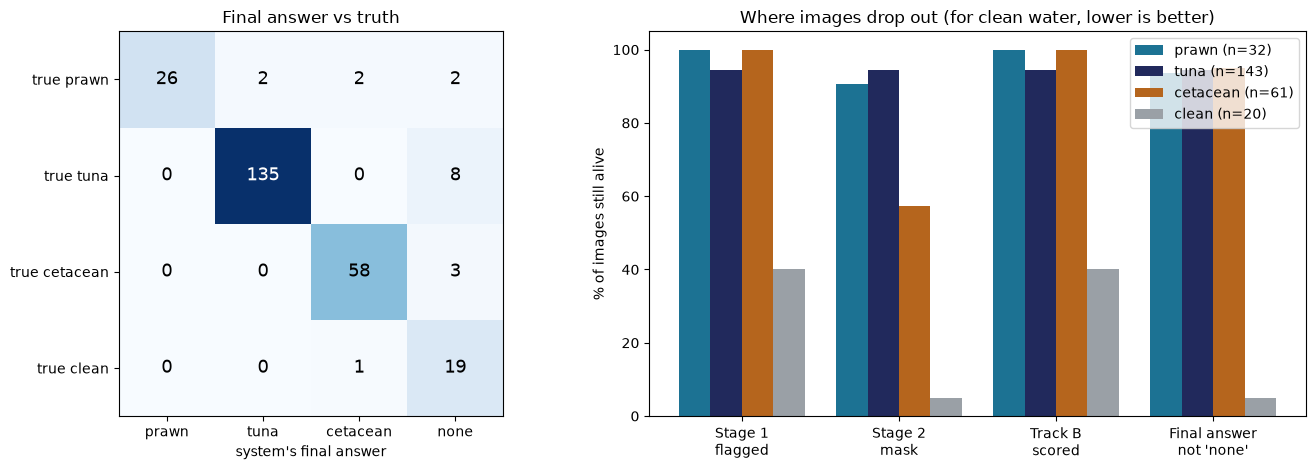

In [13]:
# --- Cell 12: One-picture summary: confusion matrix + stage-by-stage funnel ---

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

ax = axes[0]
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(4)); ax.set_xticklabels(PRED)
ax.set_yticks(range(4)); ax.set_yticklabels([f"true {t}" for t in TRUE])
ax.set_xlabel("system's final answer")
for i in range(4):
    for j in range(4):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                color="white" if cm.max() and cm[i, j] > cm.max() / 2 else "black")
ax.set_title("Final answer vs truth")

ax = axes[1]
stages = ["Stage 1\nflagged", "Stage 2\nmask", "Track B\nscored", "Final answer\nnot 'none'"]
width = 0.2
colors = {"prawn": "#1C7293", "tuna": "#21295C", "cetacean": "#B5651D", "clean": "#9AA0A6"}
for k, c in enumerate(TRUE):
    n = funnel[c][0]
    vals = [100 * v / n if n else 0 for v in funnel[c][1:]]
    ax.bar(np.arange(4) + (k - 1.5) * width, vals, width, label=f"{c} (n={n})", color=colors[c])
ax.set_xticks(range(4)); ax.set_xticklabels(stages)
ax.set_ylabel("% of images still alive"); ax.set_ylim(0, 105)
ax.set_title("Where images drop out (for clean water, lower is better)")
ax.legend()

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "stage1234_confusion_and_funnel.png", dpi=130, bbox_inches="tight")
print(f"Saved {OUTPUT_DIR / 'stage1234_confusion_and_funnel.png'}")
plt.show()

18 wrong final answers out of 256


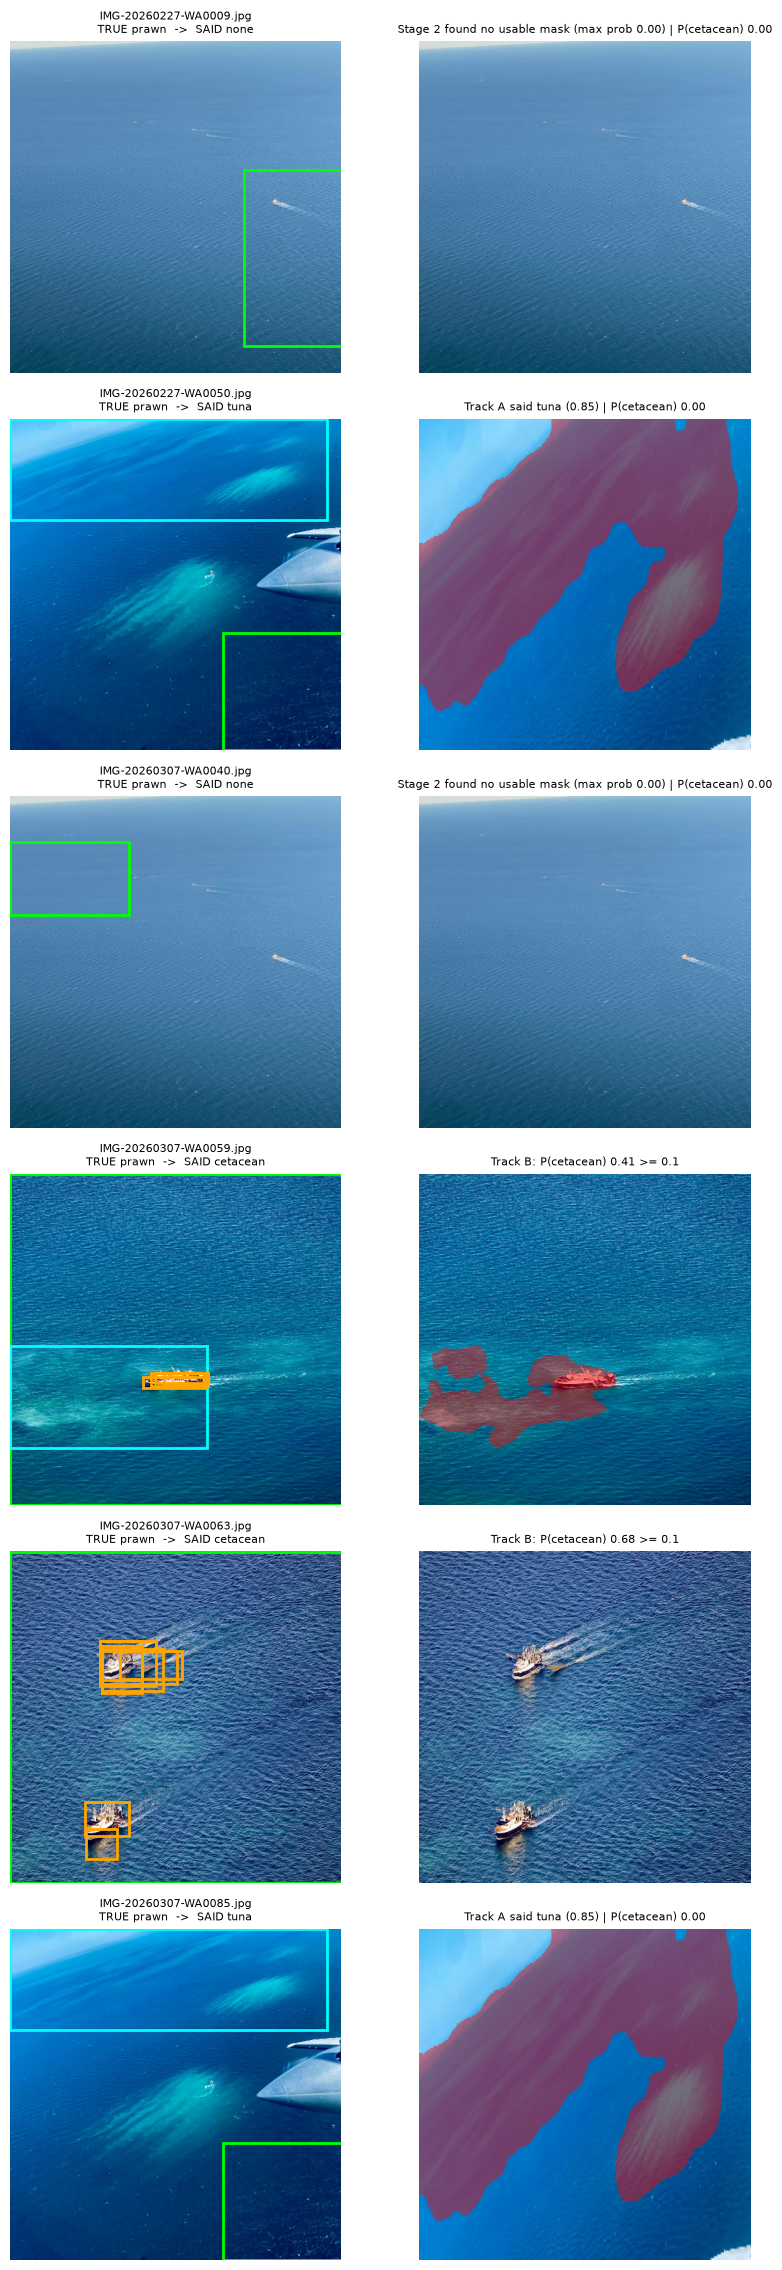

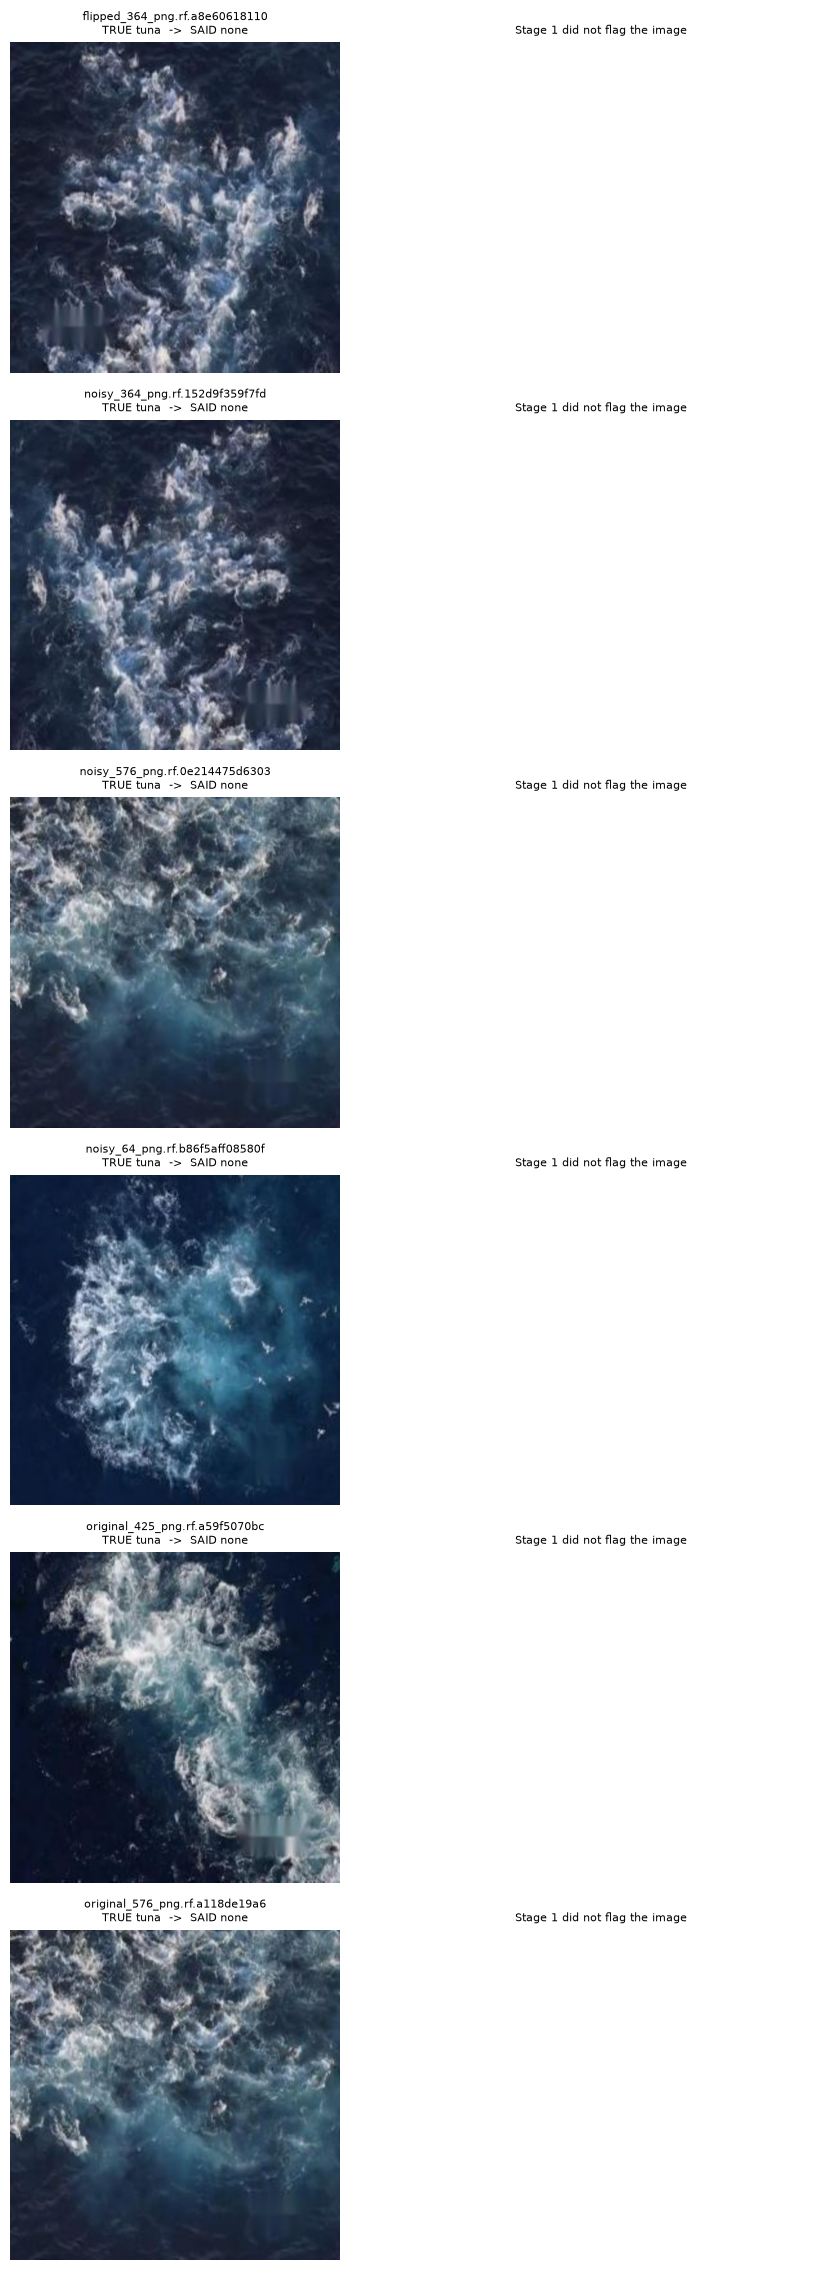

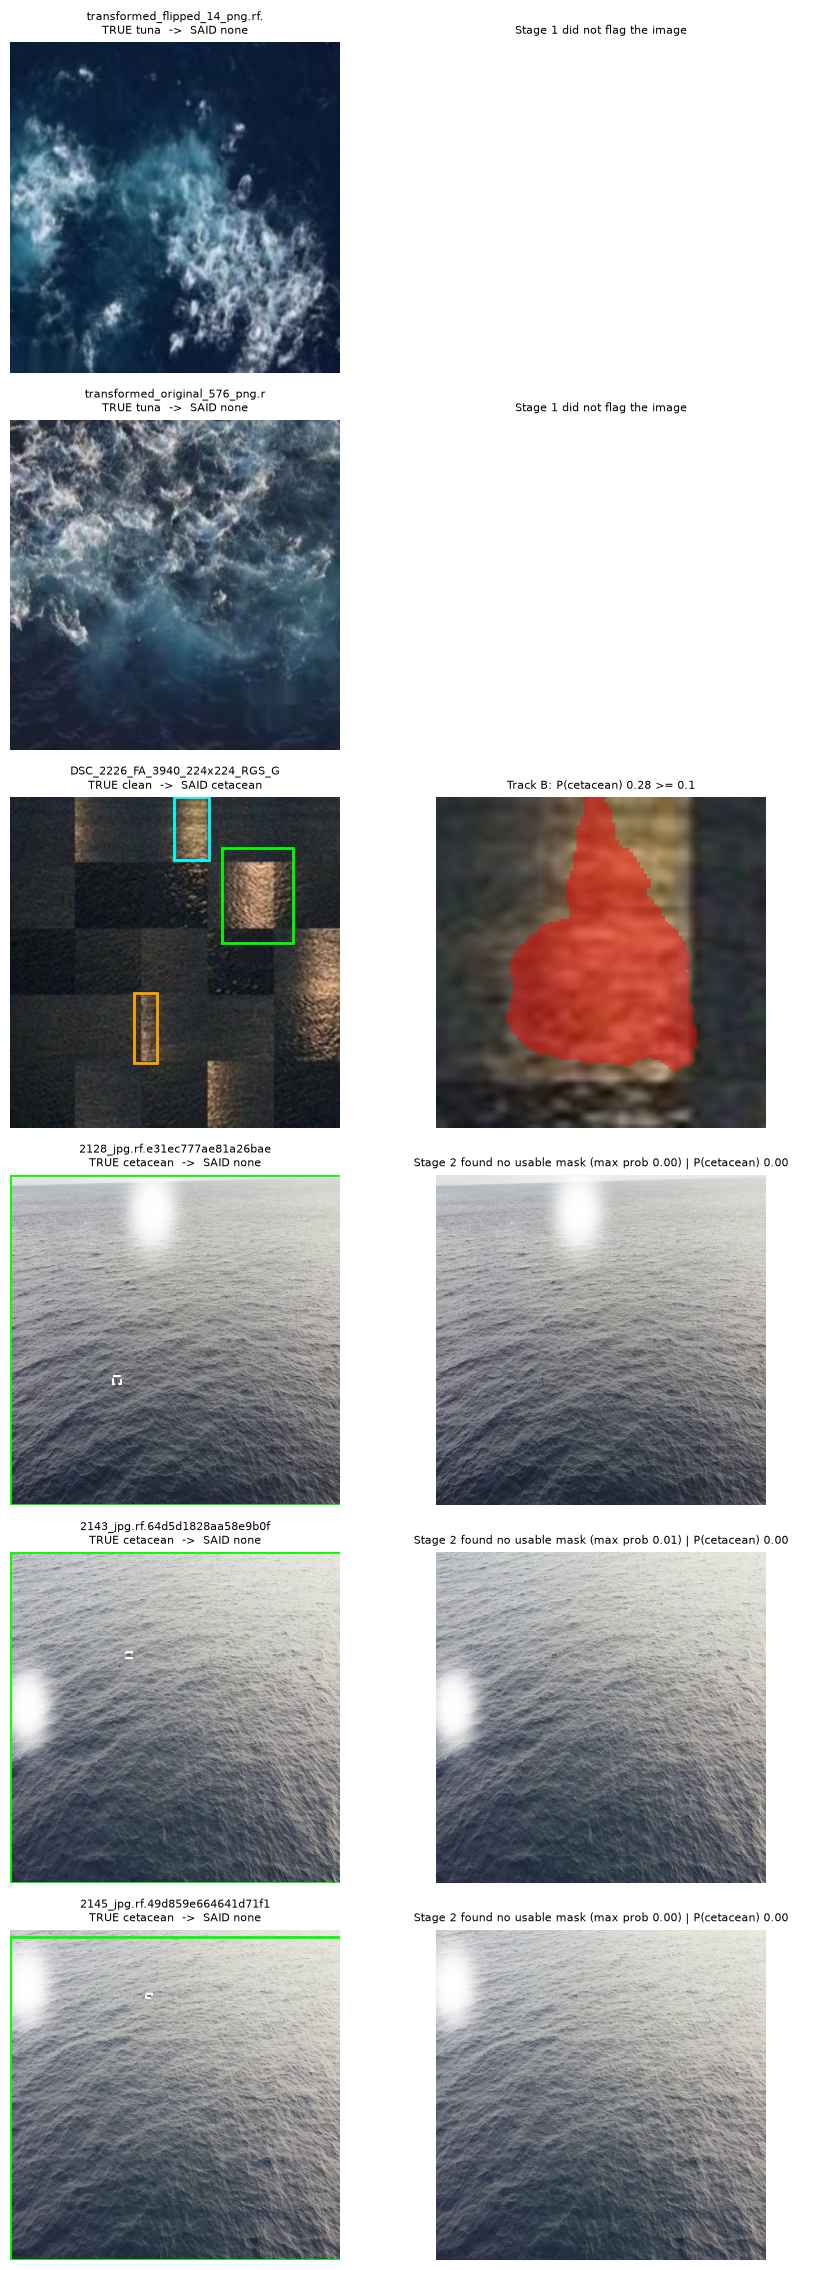

In [14]:
# --- Cell 13: Every wrong answer, with the reason ---
# Left: the frame. Green = where Stage 1 pointed. Cyan = the box around Stage 2's mask (what Track B scored when the
# source is stage2_mask). Orange = detector boxes at or above its cut-off. White = the human annotation boxes (cetacean images only).
# Right: what Track A measured, with Stage 2's mask in red (the whole frame if Stage 2 found nothing).

wrong = [r for r in records if not r["correct"] and r["true"] in TRUE]
print(f"{len(wrong)} wrong final answers out of {len(head)}")

PER_FIGURE = 6          # figures with hundreds of rows can crash the text renderer, so show them in batches
for b in range(0, len(wrong), PER_FIGURE):
    batch = wrong[b:b + PER_FIGURE]
    fig, axes = plt.subplots(len(batch), 2, figsize=(9, 3.8 * len(batch)))
    axes = np.atleast_2d(axes)
    for i, r in enumerate(batch):
        k = kept[r["path"]]
        ax = axes[i, 0]
        ax.imshow(k["rgb"]); ax.axis("off")
        for box, colour, style in [(r.get("s1_box"), "lime", "-"), (r.get("s2_box"), "cyan", "-")]:
            if box is not None:
                ax.add_patch(mpatches.Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1],
                                                fill=False, edgecolor=colour, linewidth=2, linestyle=style))
        for c_, b_ in r.get("det_boxes_512", []):
            if c_ >= DETECTOR_CONF:
                ax.add_patch(mpatches.Rectangle((b_[0], b_[1]), b_[2] - b_[0], b_[3] - b_[1], fill=False, edgecolor="orange", linewidth=2))
        for g in r.get("gt_boxes_512", []):
            ax.add_patch(mpatches.Rectangle((g[0], g[1]), g[2] - g[0], g[3] - g[1],
                                            fill=False, edgecolor="white", linewidth=1.5, linestyle="--"))
        ax.set_title(f"{Path(r['path']).name[:30]}\nTRUE {r['true']}  ->  SAID {r['final']}", fontsize=8)
        ax = axes[i, 1]
        ax.axis("off")
        if k.get("crop") is not None:
            ax.imshow(k["crop"])
            m = k["stage2_mask"]
            if m is not None and m.sum() > 0:
                overlay = np.zeros((*m.shape, 4)); overlay[m == 1] = [1, 0, 0, 0.45]
                ax.imshow(overlay)
        ax.set_title(r["reason"][:80], fontsize=8)
    plt.tight_layout()
    plt.show()

In [15]:
# --- Cell 14: Cetacean images only - how good is Track B on the human boxes, and where do Stage 1 and Stage 2 point? ---
# Track B on the annotation boxes is the best case (it is what Track B was trained and scored on). The gap between that
# and the pipeline's result is the cost of Stage 1 and Stage 2 not yet outlining cetaceans the way a person does.

cet = by_class("cetacean")
if not cet:
    print("No labelled cetacean images were scored - nothing to analyse.")
else:
    box_p, per_image = [], []
    for r in cet:
        try:
            tb = TrackBImage(r["path"])
        except Exception as e:
            print("could not open", Path(r["path"]).name, e)
            continue
        ps = [tb.p_cetacean_native(b) for b in r["gt_boxes_native"]]
        r["p_cetacean"]["annotation"] = max([p for p in ps if p is not None], default=None)
        box_p += [p for p in ps if p is not None]
        per_image.append([p for p in ps if p is not None])
    n_boxes = sum(len(r["gt_boxes_native"]) for r in cet)
    print(f"{len(cet)} labelled cetacean images, {n_boxes} annotated animals ({len(box_p)} measurable by Track B)\n")

    print(f"A. TRACK B ON THE HUMAN BOXES (best case), cut-off {TRACK_B_TAU}")
    caught = sum(p >= TRACK_B_TAU for p in box_p)
    print(f"   animals caught:               {rate(caught, len(box_p))}")
    all_c = sum(all(p >= TRACK_B_TAU for p in ps) for ps in per_image if ps)
    any_c = sum(any(p >= TRACK_B_TAU for p in ps) for ps in per_image if ps)
    n_img = sum(1 for ps in per_image if ps)
    print(f"   images with EVERY animal caught: {rate(all_c, n_img)}")
    print(f"   images with at least one caught: {rate(any_c, n_img)}")

    print("\nB. WHERE STAGE 1 AND STAGE 2 POINT, compared with the annotated animals (512x512 frame)")
    s1 = [r for r in cet if r["s1_box"] is not None]
    print(f"   Stage 1 flagged:               {rate(len(s1), len(cet))}")
    if s1:
        shares = [box_area_share(r["s1_box"]) for r in s1]
        print(f"   Stage 1 box covers (median):   {100 * np.median(shares):.0f}% of the frame "
              f"(a box that big is saying 'the whole picture looks unfamiliar', not locating an animal)")
        hit1 = sum(any(box_iou(r["s1_box"], g) >= 0.3 for g in r["gt_boxes_512"]) for r in s1)
        print(f"   Stage 1 box overlaps an animal (IoU >= 0.3): {rate(hit1, len(s1))}")
    s2 = [r for r in cet if r["s2_box"] is not None]
    print(f"   Stage 2 produced a mask:       {rate(len(s2), len(cet))}")
    if s2:
        shares = [box_area_share(r["s2_box"]) for r in s2]
        print(f"   Stage 2 mask box covers (median): {100 * np.median(shares):.0f}% of the frame")
        hit2 = sum(any(box_iou(r["s2_box"], g) >= 0.3 for g in r["gt_boxes_512"]) for r in s2)
        touch2 = sum(any(box_iou(r["s2_box"], g) > 0 for g in r["gt_boxes_512"]) for r in s2)
        print(f"   Stage 2 box overlaps an animal (IoU >= 0.3): {rate(hit2, len(s2))}")
        print(f"   Stage 2 box touches an animal at all:        {rate(touch2, len(s2))}")
        print("   (SegFormer was trained on prawn and tuna only, so low numbers here are expected and are the finding.)")

    print("\nC. TRACK B'S P(cetacean) ON THE REGION EACH SOURCE GAVE IT (cetacean images)")
    for src in ("annotation", "stage2_mask", "stage1"):
        ps = [r["p_cetacean"].get(src) for r in cet]
        ps = [p for p in ps if p is not None]
        if ps:
            print(f"   {src:<12}: scored {len(ps)}/{len(cet)} images; at or above {TRACK_B_TAU}: {sum(p >= TRACK_B_TAU for p in ps)}"
                  f"  (median {np.median(ps):.2f})")
        else:
            print(f"   {src:<12}: nothing scored")

61 labelled cetacean images, 227 annotated animals (227 measurable by Track B)

A. TRACK B ON THE HUMAN BOXES (best case), cut-off 0.5
   animals caught:               205/227 =  90.3%   (95% CI 86-94%)
   images with EVERY animal caught: 48/61 =  78.7%   (95% CI 66-88%)
   images with at least one caught: 57/61 =  93.4%   (95% CI 84-98%)

B. WHERE STAGE 1 AND STAGE 2 POINT, compared with the annotated animals (512x512 frame)
   Stage 1 flagged:               61/61 = 100.0%   (95% CI 94-100%)
   Stage 1 box covers (median):   100% of the frame (a box that big is saying 'the whole picture looks unfamiliar', not locating an animal)
   Stage 1 box overlaps an animal (IoU >= 0.3): 0/61 =   0.0%   (95% CI 0-6%)
   Stage 2 produced a mask:       35/61 =  57.4%   (95% CI 44-70%)
   Stage 2 mask box covers (median): 41% of the frame
   Stage 2 box overlaps an animal (IoU >= 0.3): 3/35 =   8.6%   (95% CI 2-23%)
   Stage 2 box touches an animal at all:        28/35 =  80.0%   (95% CI 63-92%)
   

In [16]:
# --- Cell 14b: EXPERIMENT - can Track B find the cetaceans itself, without Stage 2's box? ---
# Why: cell 14 shows Track B catches most animals when it is given a human-drawn box, but Stage 2 (trained on prawn and tuna only)
# draws boxes that cover about half the frame, so Track B sees no animal in them. Here Track B is slid over the picture in
# animal-sized windows and the best-scoring window is taken as the answer. REPORTING ONLY: the final answer in cell 9 is unchanged.
# Do not pick a cut-off from this table (that would tune on the test images); it only shows whether the idea is worth building.

RUN_WINDOW_SEARCH = False   # tried once: Track B could not tell cetaceans from prawn / tuna by sliding windows (AUC 0.22 vs prawn, 0.52 vs tuna). Left here for reference.
WINDOW_FRACTIONS = (0.06, 0.10, 0.16, 0.25)   # window side as a share of the picture's shorter side (annotated animals are mostly 5-17%)
WINDOW_STRIDE = 0.6                           # step as a share of the window side
WINDOW_CUTOFFS = (0.80, 0.90, 0.95, 0.98, 0.99)

def window_scan(path):
    tb = TrackBImage(path)
    cx0, cy0, cx1, cy1 = tb.content
    short = min(cx1 - cx0, cy1 - cy0)
    boxes, feats_rows = [], []
    for f in WINDOW_FRACTIONS:
        side = int(round(f * short))
        if side < 8:
            continue
        step = max(1, int(side * WINDOW_STRIDE))
        for y in range(cy0, cy1 - side + 1, step):
            for x in range(cx0, cx1 - side + 1, step):
                ft = extract_box_features(tb.img, (x, y, x + side, y + side), content=tb.content, lab=tb.lab)
                if ft is None:
                    continue
                boxes.append((x, y, x + side, y + side))
                feats_rows.append([ft[c] for c in TRACK_B_COLS])
    if not feats_rows:
        return None, None
    P = TRACK_B_MODEL.predict_proba(np.array(feats_rows, dtype=float))[:, TRACK_B_POS]
    return P, boxes

def _centre_inside(box, gts, grow=0.5):
    cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
    for g in gts:
        gw, gh = g[2] - g[0], g[3] - g[1]
        if g[0] - grow * gw <= cx <= g[2] + grow * gw and g[1] - grow * gh <= cy <= g[3] + grow * gh:
            return True
    return False

if not RUN_WINDOW_SEARCH:
    print("Skipped (RUN_WINDOW_SEARCH is False).")
else:
    todo = [r for r in records if r["stage1_flagged"]]
    print(f"Sliding Track B over {len(todo)} images that Stage 1 flagged (about 1 second each)...")
    t0, n_err = time.time(), 0
    for r in records:
        r["win_max"], r["win_box"] = 0.0, None
    for i, r in enumerate(todo, start=1):
        try:
            P, boxes = window_scan(r["path"])
            if P is not None:
                j = int(np.argmax(P))
                r["win_max"], r["win_box"] = float(P[j]), boxes[j]
        except Exception as e:
            n_err += 1
        if i % 25 == 0 or i == len(todo):
            el = time.time() - t0
            print(f"  ...{i}/{len(todo)} ({el:.0f}s, about {el / i * (len(todo) - i):.0f}s left)")
    if n_err:
        print(f"WARNING: {n_err} image(s) could not be scanned and count as score 0.")

    ALL_C = ["prawn", "tuna", "cetacean", "clean", "cetacean_empty"]
    print("\nA. HOW WELL DOES THE BEST WINDOW SEPARATE CETACEANS FROM THE REST?  (score = highest P(cetacean) over all windows)")
    print(f"   {'group':<16}{'images':>7}{'median':>9}{'90th pct':>10}")
    for c in ALL_C:
        v = np.array([r["win_max"] for r in records if r["true"] == c])
        if v.size:
            print(f"   {c:<16}{v.size:>7}{np.median(v):>9.2f}{np.percentile(v, 90):>10.2f}")
    try:
        from sklearn.metrics import roc_auc_score
        pos = np.array([r["win_max"] for r in records if r["true"] == "cetacean"])
        for c in ("prawn", "tuna", "clean", "cetacean_empty"):
            neg = np.array([r["win_max"] for r in records if r["true"] == c])
            if pos.size and neg.size:
                y = np.r_[np.ones(pos.size), np.zeros(neg.size)]
                print(f"   AUC cetacean vs {c:<15}: {roc_auc_score(y, np.r_[pos, neg]):.2f}   (0.5 = no separation, 1.0 = perfect)")
    except Exception as e:
        print("   (AUC skipped:", e, ")")

    print("\nB. DETECTION AND FALSE ALARMS BY CUT-OFF  (an image counts as 'cetacean' if its best window is at or above the cut-off)")
    print(f"   {'cut-off':<9}{'cetacean found':>16}{'  top window on an animal':>26}{'prawn':>9}{'tuna':>9}{'clean':>9}{'empty-label':>13}")
    cet_r = [r for r in records if r["true"] == "cetacean"]
    for cut in WINDOW_CUTOFFS:
        found = [r for r in cet_r if r["win_max"] >= cut]
        on_animal = [r for r in found if r["win_box"] is not None and _centre_inside(r["win_box"], r["gt_boxes_native"])]
        fa = {c: sum(r["win_max"] >= cut for r in records if r["true"] == c) for c in ("prawn", "tuna", "clean", "cetacean_empty")}
        n = {c: sum(1 for r in records if r["true"] == c) for c in fa}
        print(f"   {cut:<9}{len(found):>8}/{len(cet_r):<7}{len(on_animal):>16}/{len(cet_r):<9}"
              + "".join(f"{fa[c]:>5}/{n[c]:<3}" for c in ("prawn", "tuna", "clean")) + f"{fa['cetacean_empty']:>7}/{n['cetacean_empty']:<4}")

    print("\nC. WHOLE SYSTEM IF THIS RULE REPLACED TRACK B ON STAGE 2'S BOX   (window says cetacean -> cetacean, otherwise Track A as before)")
    print(f"   {'setting':<34}" + "".join(f"{c:>12}" for c in TRUE) + f"{'overall':>12}")
    def _row(label, fn):
        ok_all, n_all, cells_ = 0, 0, []
        for c in TRUE:
            rs = by_class(c)
            ok = sum(fn(r) == EXPECTED[c] for r in rs)
            ok_all += ok; n_all += len(rs)
            cells_.append(f"{ok}/{len(rs)}")
        print(f"   {label:<34}" + "".join(f"{x:>12}" for x in cells_) + f"{100 * ok_all / max(1, n_all):>11.1f}%")
    _row("Track A only", lambda r: decide(r, use_track_b=False)[0])
    _row(f"current: Track B on Stage 2 box, {TRACK_B_TAU}", lambda r: decide(r)[0])
    for cut in WINDOW_CUTOFFS:
        _row(f"window search, cut-off {cut}",
             lambda r, cut=cut: "cetacean" if r["win_max"] >= cut else decide(r, use_track_b=False)[0])
    print("\n   Read it like this: if cetacean images are found at a cut-off where prawn / tuna / clean false alarms stay near zero, the idea works and"
          "\n   the cut-off should then be chosen on separate calibration pictures. If false alarms rise as fast as detections, Track B cannot find"
          "\n   animals on its own and Stage 2 needs to learn cetaceans.")

Skipped (RUN_WINDOW_SEARCH is False).


In [17]:
# --- Cell 15 (optional): How often does Track B wrongly say 'cetacean' on Val_data tuna and sea frames? ---
# Set RUN_CALIBRATION = True in cell 1 to run. These folders were used to train Track A, so they are NOT valid for
# judging Track A. They are fine for this question because Track B has never seen them. It shows how high the cut-off
# has to be to keep wrong cetacean calls low, without touching the test images.

if not RUN_CALIBRATION:
    print("Skipped (RUN_CALIBRATION is False in cell 1).")
else:
    calib = {}
    for cls, folder in CALIBRATION_DIRS.items():
        paths = list_images(folder)
        paths = random.Random(7).sample(paths, min(CALIBRATION_N, len(paths)))
        print(f"{cls}: scoring {len(paths)} images from {folder}")
        rows = []
        for i, p in enumerate(paths, start=1):
            try:
                rec, _ = score_image(p)
                rows.append(rec)
            except Exception as e:
                print("  skipped", p.name, repr(e))
            if i % 25 == 0:
                print(f"  ...{i}/{len(paths)}")
        calib[cls] = rows

    print(f"\nShare of images Track B would call 'cetacean' (Track B box = {TRACK_B_BOX_SOURCE}; images Stage 1/2 never reach count as not cetacean)")
    print(f"{'cut-off':>8}" + "".join(f"{c:>16}" for c in calib))
    for tau in TAU_GRID + [0.95, 0.99]:
        line = f"{tau:>8}"
        for cls, rows in calib.items():
            k = sum(1 for r in rows if (r["p_cetacean"].get(TRACK_B_BOX_SOURCE) or 0) >= tau)
            line += f"{k}/{len(rows)} ({100 * k / max(1, len(rows)):.0f}%)".rjust(16)
        print(line)

Skipped (RUN_CALIBRATION is False in cell 1).


In [18]:
# --- Cell 16: Save the results ---

with open(OUTPUT_DIR / "stage1234_per_image_results.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["path", "true", "expected", "final", "correct", "ended_at", "reason", "stage1_flagged", "stage2_mask_px",
                "stage2_max_prob", "p_cetacean_stage2_box", "p_cetacean_stage1_box", "p_cetacean_annotation_box",
                "p_cetacean_used", "n_annotated_animals"] + [f"trackA_prob_{c}" for c in TRACK_A_CLASSES])
    for r in records:
        probs = r["track_a_probs"] or {}
        pc = r["p_cetacean"]
        w.writerow([r["path"], r["true"], r["expected"], r["final"], r["correct"], r["ended_at"], r["reason"], r["stage1_flagged"],
                    r["stage2_mask_px"], r["stage2_max_prob"], pc.get("stage2_mask"), pc.get("stage1"), pc.get("annotation"),
                    track_b_p(r), len(r.get("gt_boxes_native", []))] + [probs.get(c, "") for c in TRACK_A_CLASSES])

if audit_rows:
    with open(OUTPUT_DIR / "stage1234_lookalike_audit.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(audit_rows[0].keys()))
        w.writeheader()
        w.writerows(audit_rows)

summary["settings"] = {"track_b_box_source": TRACK_B_BOX_SOURCE, "track_b_tau": TRACK_B_TAU, "stage2_route": STAGE2_ROUTE,
                       "stage2_whole_frame_prob": STAGE2_WHOLE_FRAME_PROB, "track_a_guard": mine}
summary["track_a_feature_set"] = bundle["feature_set"]
summary["track_b_feature_set"] = bundle_b["feature_set"]
with open(OUTPUT_DIR / "stage1234_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(f"Saved results to {OUTPUT_DIR.resolve()}:")
for p in sorted(OUTPUT_DIR.glob("stage1234_*")):
    print(f"  {p.name}")

Saved results to C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Combined Pipeline\stage1234_test_output:
  stage1234_confusion_and_funnel.png
  stage1234_lookalike_audit.csv
  stage1234_per_image_results.csv
  stage1234_summary.json
